## Import bibliotek

In [1]:
%pip install seaborn
%pip install ydata-profiling
%pip install xgboost catboost bayesian-optimization

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
#Podstawowe biblioteki użyte do eksploracji danych
import pandas as pd
import numpy  as np
import math
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from ydata_profiling import ProfileReport

#Biblioteki potrzebne do wizualizacji
import plotly.express as px
import plotly.figure_factory as ff
import plotly.graph_objects as go

#Biblioteki związane z transformacją danych i przygotowanie próbki treningowej i testowej
from sklearn.preprocessing import StandardScaler, OneHotEncoder,RobustScaler
from sklearn.pipeline import make_pipeline, FeatureUnion, Pipeline
from sklearn.base import TransformerMixin, BaseEstimator
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from pandas.api.types import CategoricalDtype

#Biblioteki zawierające gotowe implementacje modeli
from sklearn.linear_model import LogisticRegression 
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV,train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import ExtraTreesClassifier
from catboost import CatBoostClassifier
import lightgbm as lgb
from lightgbm import LGBMRegressor
from bayes_opt import BayesianOptimization
from sklearn.model_selection import KFold, cross_val_score
from lightgbm import LGBMClassifier

#Biblioteki zawierające metryki oraz metody selekcji zmiennych
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, roc_curve, precision_recall_curve, classification_report, make_scorer)
from sklearn.feature_selection import SelectKBest, f_regression, RFECV, f_classif, chi2

In [3]:
import joblib
import random
import warnings
warnings.filterwarnings('ignore')

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)

## Wszczytanie danych

In [4]:
data = pd.read_csv(r"C:\Users\klaud\OneDrive\Desktop\credit_risk_dataset.csv") 

In [5]:
data_original =  pd.read_csv(r"C:\Users\klaud\OneDrive\Desktop\credit_risk_dataset.csv") 

In [6]:
data.columns = data.columns.str.replace(' ', '_')

## Eksploracja danych

In [7]:
print("Rozmiar data:", data.shape)
display(data.head())
display(data.info())

Rozmiar data: (32581, 12)


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


None

| Nazwa zmiennej                 | Opis                                               | Możliwe wartości / znaczenie                                                                                                       |
| ------------------------------ | -------------------------------------------------- | ---------------------------------------------------------------------------------------------------------------------------------- |
| **person_age**                 | Wiek osoby aplikującej o kredyt                    | liczba                                                                                                                             |
| **person_income**              | Roczny dochód osoby                                | liczba                                                                                                                             |
| **person_home_ownership**      | Forma posiadania nieruchomości                     | rent – wynajem<br>mortgage – kredyt hipoteczny<br>own – własność<br>other – inna forma                                             |
| **person_emp_length**          | Długość zatrudnienia (w latach)                    | liczba                                                                                                                             |
| **loan_intent**                | Cel zaciągania kredytu                             | kategoria (np. edukacja, medyczny, biznes itp.)                                                                                    |
| **loan_grade**                 | Ocena ryzyka kredytowego                           | A – bardzo niskie ryzyko<br>B – niskie<br>C – umiarkowane<br>D – podwyższone<br>E – wysokie<br>F – bardzo wysokie<br>G – najwyższe |
| **loan_amnt**                  | Kwota kredytu                                      | liczba                                                                                                                             |
| **loan_int_rate**              | Oprocentowanie kredytu                             | liczba (%)                                                                                                                         |
| **loan_status**                | Czy kredyt zakończył się niewypłacalnością         | 0 – brak niewypłacalności (spłacony)<br>1 – niewypłacalność (default)                                                              |
| **loan_percent_income**        | Procent dochodu stanowiący kwotę kredytu           | liczba                                                                                                                             |
| **cb_person_default_on_file**  | Historia niewypłacalności w rejestrach kredytowych | Y – ma historię<br>N – brak historii                                                                                               |
| **cb_person_cred_hist_length** | Długość historii kredytowej                        | liczba (lata)                                                                                                                      |


In [8]:
# Lista typowych nazw targetów w datasetach credit risk
possible_targets = ['loan_status','loan_status_binary','loan_status (original)','default','loan_condition',
                    'target','status','Class','loan_status_loan_condition','is_default','loan_default','bad_ind','loan_status_label']

found = [c for c in data.columns if c.lower() in [p.lower() for p in possible_targets]]
chosen_target = None
# jeśli znaleziono, wybieram najbardziej binarną kolumnę (0/1 or two unique values)
if found:
    for c in found:
        uniq = data[c].dropna().unique()
        if len(uniq) <= 3:
            chosen_target = c
            break
    if chosen_target is None:
        chosen_target = found[0]

# jeżeli nie znaleziono, szukamy kolumny z 2 unikalnymi wartościami
if chosen_target is None:
    binary_cols = [c for c in data.columns if data[c].nunique() == 2]
    candidates = [c for c in binary_cols if any(w in c.lower() for w in ['loan','default','status','churn','bad'])]
    if candidates:
        chosen_target = candidates[0]
    elif binary_cols:
        chosen_target = binary_cols[0]

if chosen_target is None:
    raise RuntimeError("Nie udało się automatycznie wykryć kolumny target. Podaj proszę ręcznie nazwę kolumny docelowej (np. TARGET='loan_status').")
else:
    target = chosen_target
    print("Wybrano target:", target)
    print("Unikalne wartości targetu i ich liczności:")
    display(data[target].value_counts(dropna=False))

Wybrano target: loan_status
Unikalne wartości targetu i ich liczności:


loan_status
0    25473
1     7108
Name: count, dtype: int64

In [9]:
null_counts = data.isnull().sum()
print("Number of null values in each column:\n{}".format(null_counts))

Number of null values in each column:
person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              895
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3116
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64


In [10]:
data.describe().round(2)

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.00,32581.00,31686.00,32581.00,29465.00,32581.00,32581.00,32581.00
mean,27.73,66074.85,4.79,9589.37,11.01,0.22,0.17,5.80
std,6.35,61983.12,4.14,6322.09,3.24,0.41,0.11,4.06
min,20.00,4000.00,0.00,500.00,5.42,0.00,0.00,2.00
25%,23.00,38500.00,2.00,5000.00,7.90,0.00,0.09,3.00
50%,26.00,55000.00,4.00,8000.00,10.99,0.00,0.15,4.00
75%,30.00,79200.00,7.00,12200.00,13.47,0.00,0.23,8.00
max,144.00,6000000.00,123.00,35000.00,23.22,1.00,0.83,30.00


| Kolumna               | Średnia / Typowy zakres | Komentarz                                                                            |
| --------------------- | ----------------------- | ------------------------------------------------------------------------------------ |
| **person_age**        | ~28 lat                 | Dane młode; większość klientów <35.                                                  |
| **person_income**     | ~66 000                 | Silnie skośny rozkład, wiele outlierów.                                              |
| **person_emp_length** | ~4–5 lat                | Przeciętny staż pracy jest umiarkowany; krótki staż (<1 roku) oznacza wyższe ryzyko. |
| **loan_amnt**         | ~9600                   | Typowe kredyty konsumpcyjne.                                                         |
| **loan_int_rate**     | ~11%                    | Realistyczne oprocentowania.                                                         |
| **loan_status**       | średnia 0.22            | 22% defaultów → dane niezbalansowane.                                                |
| **cred_hist_length**  | ~5.8 lat                | Krótka historia kredytowa większości osób.                                           |



In [11]:
#Automatyczne wykrycie cech numerycznych i kategorycznych
Kolumny_numeryczne = data.select_dtypes(include=[np.number]).columns.tolist()
if target in Kolumny_numeryczne:
    Kolumny_numeryczne.remove(target)

Kolumny_tekstowe = data.select_dtypes(include=['object','category','bool']).columns.tolist()
if target in Kolumny_tekstowe:
    Kolumny_tekstowe.remove(target)
print("Liczba cech numerycznych:", len(Kolumny_numeryczne))
print("Liczba cech kategorycznych:", len(Kolumny_tekstowe))
print("Przykładowe cechy numeryczne:", Kolumny_numeryczne[:10])
print("Przykładowe cechy kategoryczne:", Kolumny_tekstowe[:10])

Liczba cech numerycznych: 7
Liczba cech kategorycznych: 4
Przykładowe cechy numeryczne: ['person_age', 'person_income', 'person_emp_length', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length']
Przykładowe cechy kategoryczne: ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']


## Przegląd merytoryczny

In [12]:
# Rozkład targetu, proporcje klas
print("Proporcje klas targetu:")
display(data[target].value_counts(normalize=True))

Proporcje klas targetu:


loan_status
0    0.781836
1    0.218164
Name: proportion, dtype: float64

In [13]:
licz = data.loan_status.value_counts()
płaci = licz.get(0,0)
nie_płaci = licz.get(1,0)
procent = (płaci/len(data))*100
print(f'Liczba osób spłacających treminowo:{płaci}')
print(f'Liczba osób niespłacających terminowo: {nie_płaci}')
print(f"Osoby spłacające kredyty bez żadnych opóźnień {round(procent,2)}% wszystkich wniosków")

Liczba osób spłacających treminowo:25473
Liczba osób niespłacających terminowo: 7108
Osoby spłacające kredyty bez żadnych opóźnień 78.18% wszystkich wniosków


In [14]:
a = data.nunique()
b = len(data)
c = data.duplicated().sum()

print(f"Ilość unikalnych wartości to {a}")
print(f"Ilość wszystkich rekordów to {b}")
print(f"Ilość duplikatów to {c}")

Ilość unikalnych wartości to person_age                      58
person_income                 4295
person_home_ownership            4
person_emp_length               36
loan_intent                      6
loan_grade                       7
loan_amnt                      753
loan_int_rate                  348
loan_status                      2
loan_percent_income             77
cb_person_default_on_file        2
cb_person_cred_hist_length      29
dtype: int64
Ilość wszystkich rekordów to 32581
Ilość duplikatów to 165


In [15]:
data = data.drop_duplicates()
#Usunięto duplikaty w danych, ponieważ każda obserwacja w zbiorze reprezentuje unikalny wniosek kredytowy. 
#Powtarzające się wiersze mogłyby wprowadzać sztuczne powielenie informacji i zafałszować model predykcyjny, dlatego zostały usunięte.

In [16]:
display(data[data.duplicated(keep=False)])

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length


## Analiza danych kategorycznych

In [17]:
Kolumny_tekstowe

['person_home_ownership',
 'loan_intent',
 'loan_grade',
 'cb_person_default_on_file']

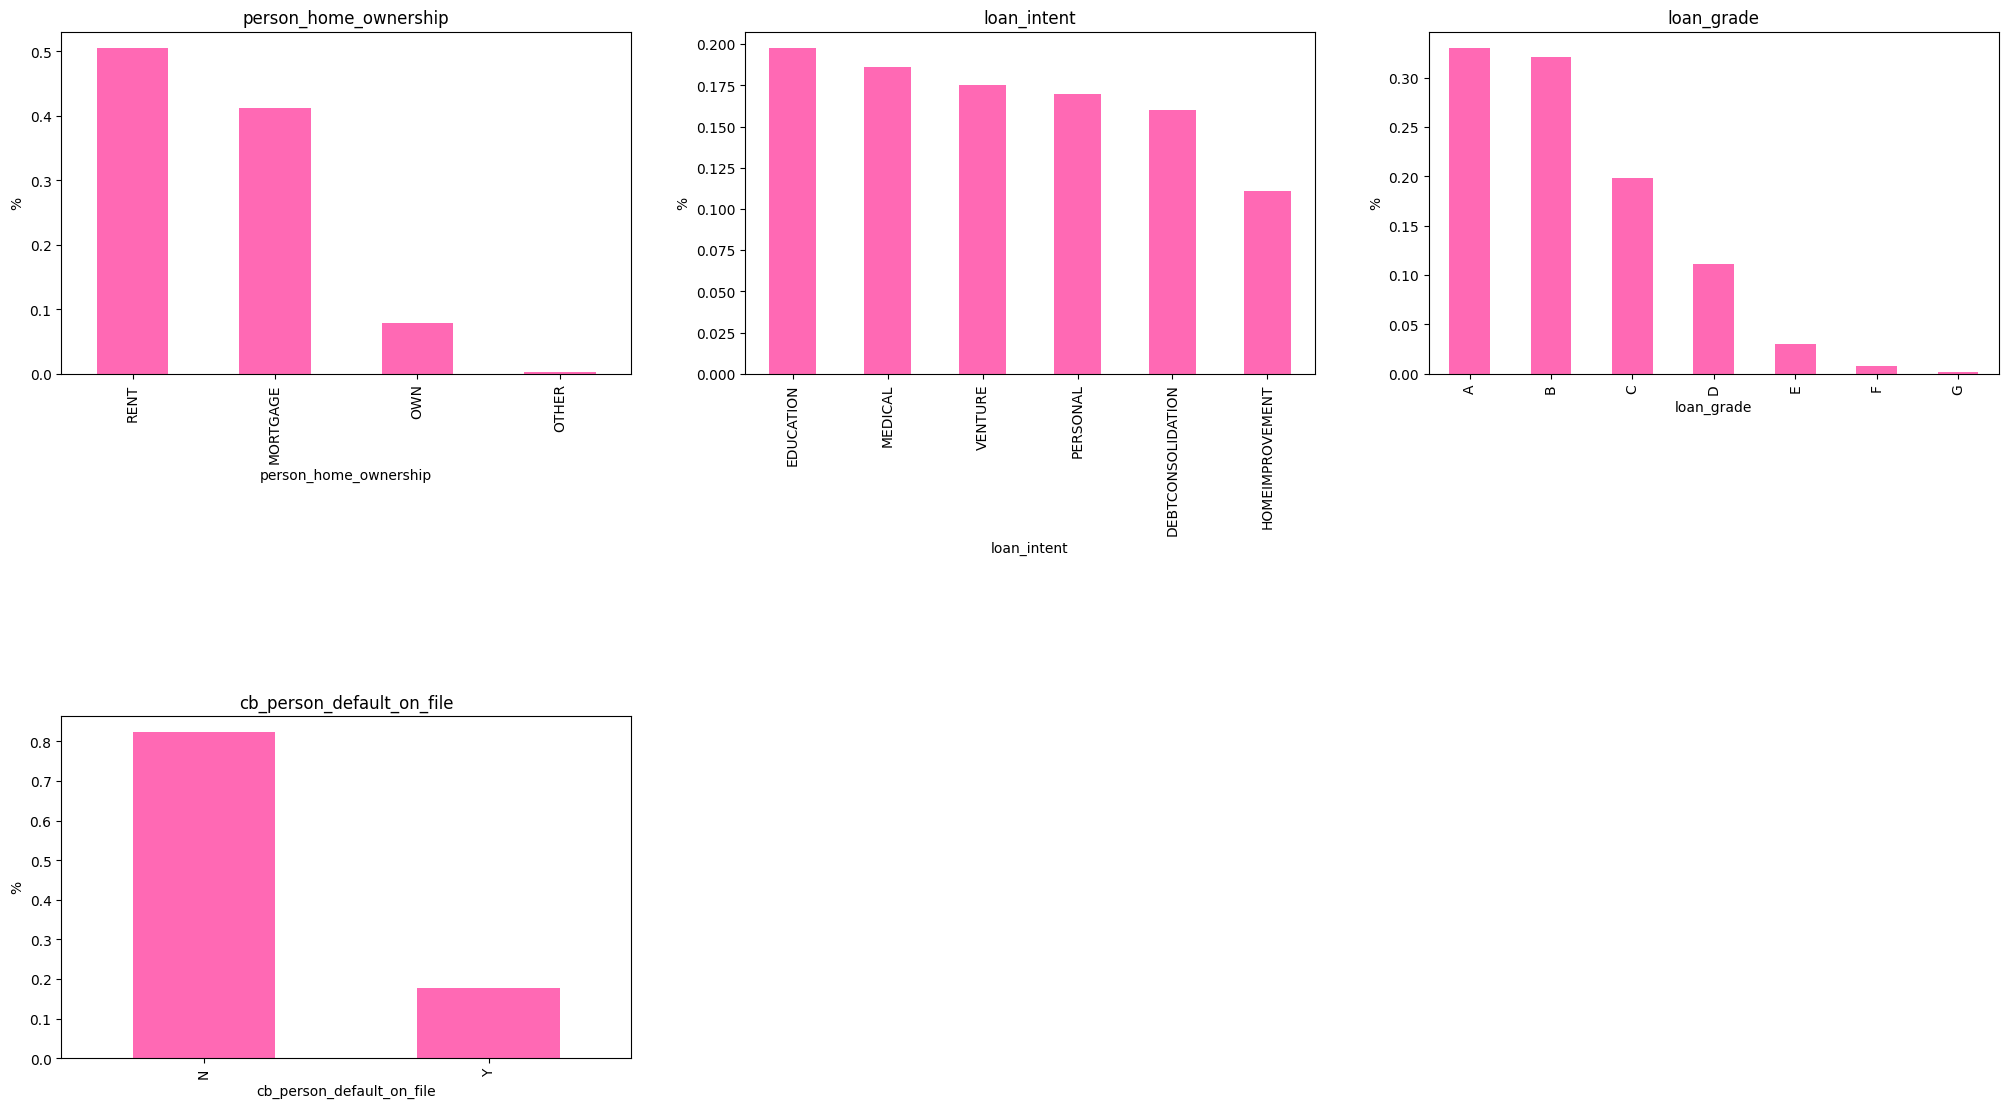

In [18]:
fig = plt.figure(figsize=(25,40))
for i , cecha in enumerate(Kolumny_tekstowe):
    ax = fig.add_subplot(5,3,i+1)
    ax.set_title(cecha)
    (data[cecha].value_counts()/len(data[cecha])).plot.bar(color ='#FF69B4')
    ax.set(ylabel="%")  
plt.subplots_adjust(hspace = 1, wspace = 0.2)
plt.show()

In [19]:
custom_pink = ['#FFE6F2','#FFB6C1','#FF69B4','#FF1493','#C71585', '#FF85A1', '#E75480']
level_counts=data.person_home_ownership.value_counts()
fig = px.pie(values=level_counts.values,
          names=level_counts.index,
          color_discrete_sequence=custom_pink,
          title= 'person_home_ownership'
          )
fig.update_traces(textinfo='label+percent+value', textfont_size=15,
                  marker=dict(line=dict(color='#102000', width=0.5)))
fig.update_layout(width=800, height=800)

In [20]:
fig=px.histogram(data, x = 'loan_intent',histnorm = 'percent', text_auto = '.2f',template = 'presentation', title = 'loan intent',color_discrete_sequence=custom_pink)
fig.update_layout()

## Analiza danych numerycznych

In [21]:
Kolumny_numeryczne

['person_age',
 'person_income',
 'person_emp_length',
 'loan_amnt',
 'loan_int_rate',
 'loan_percent_income',
 'cb_person_cred_hist_length']

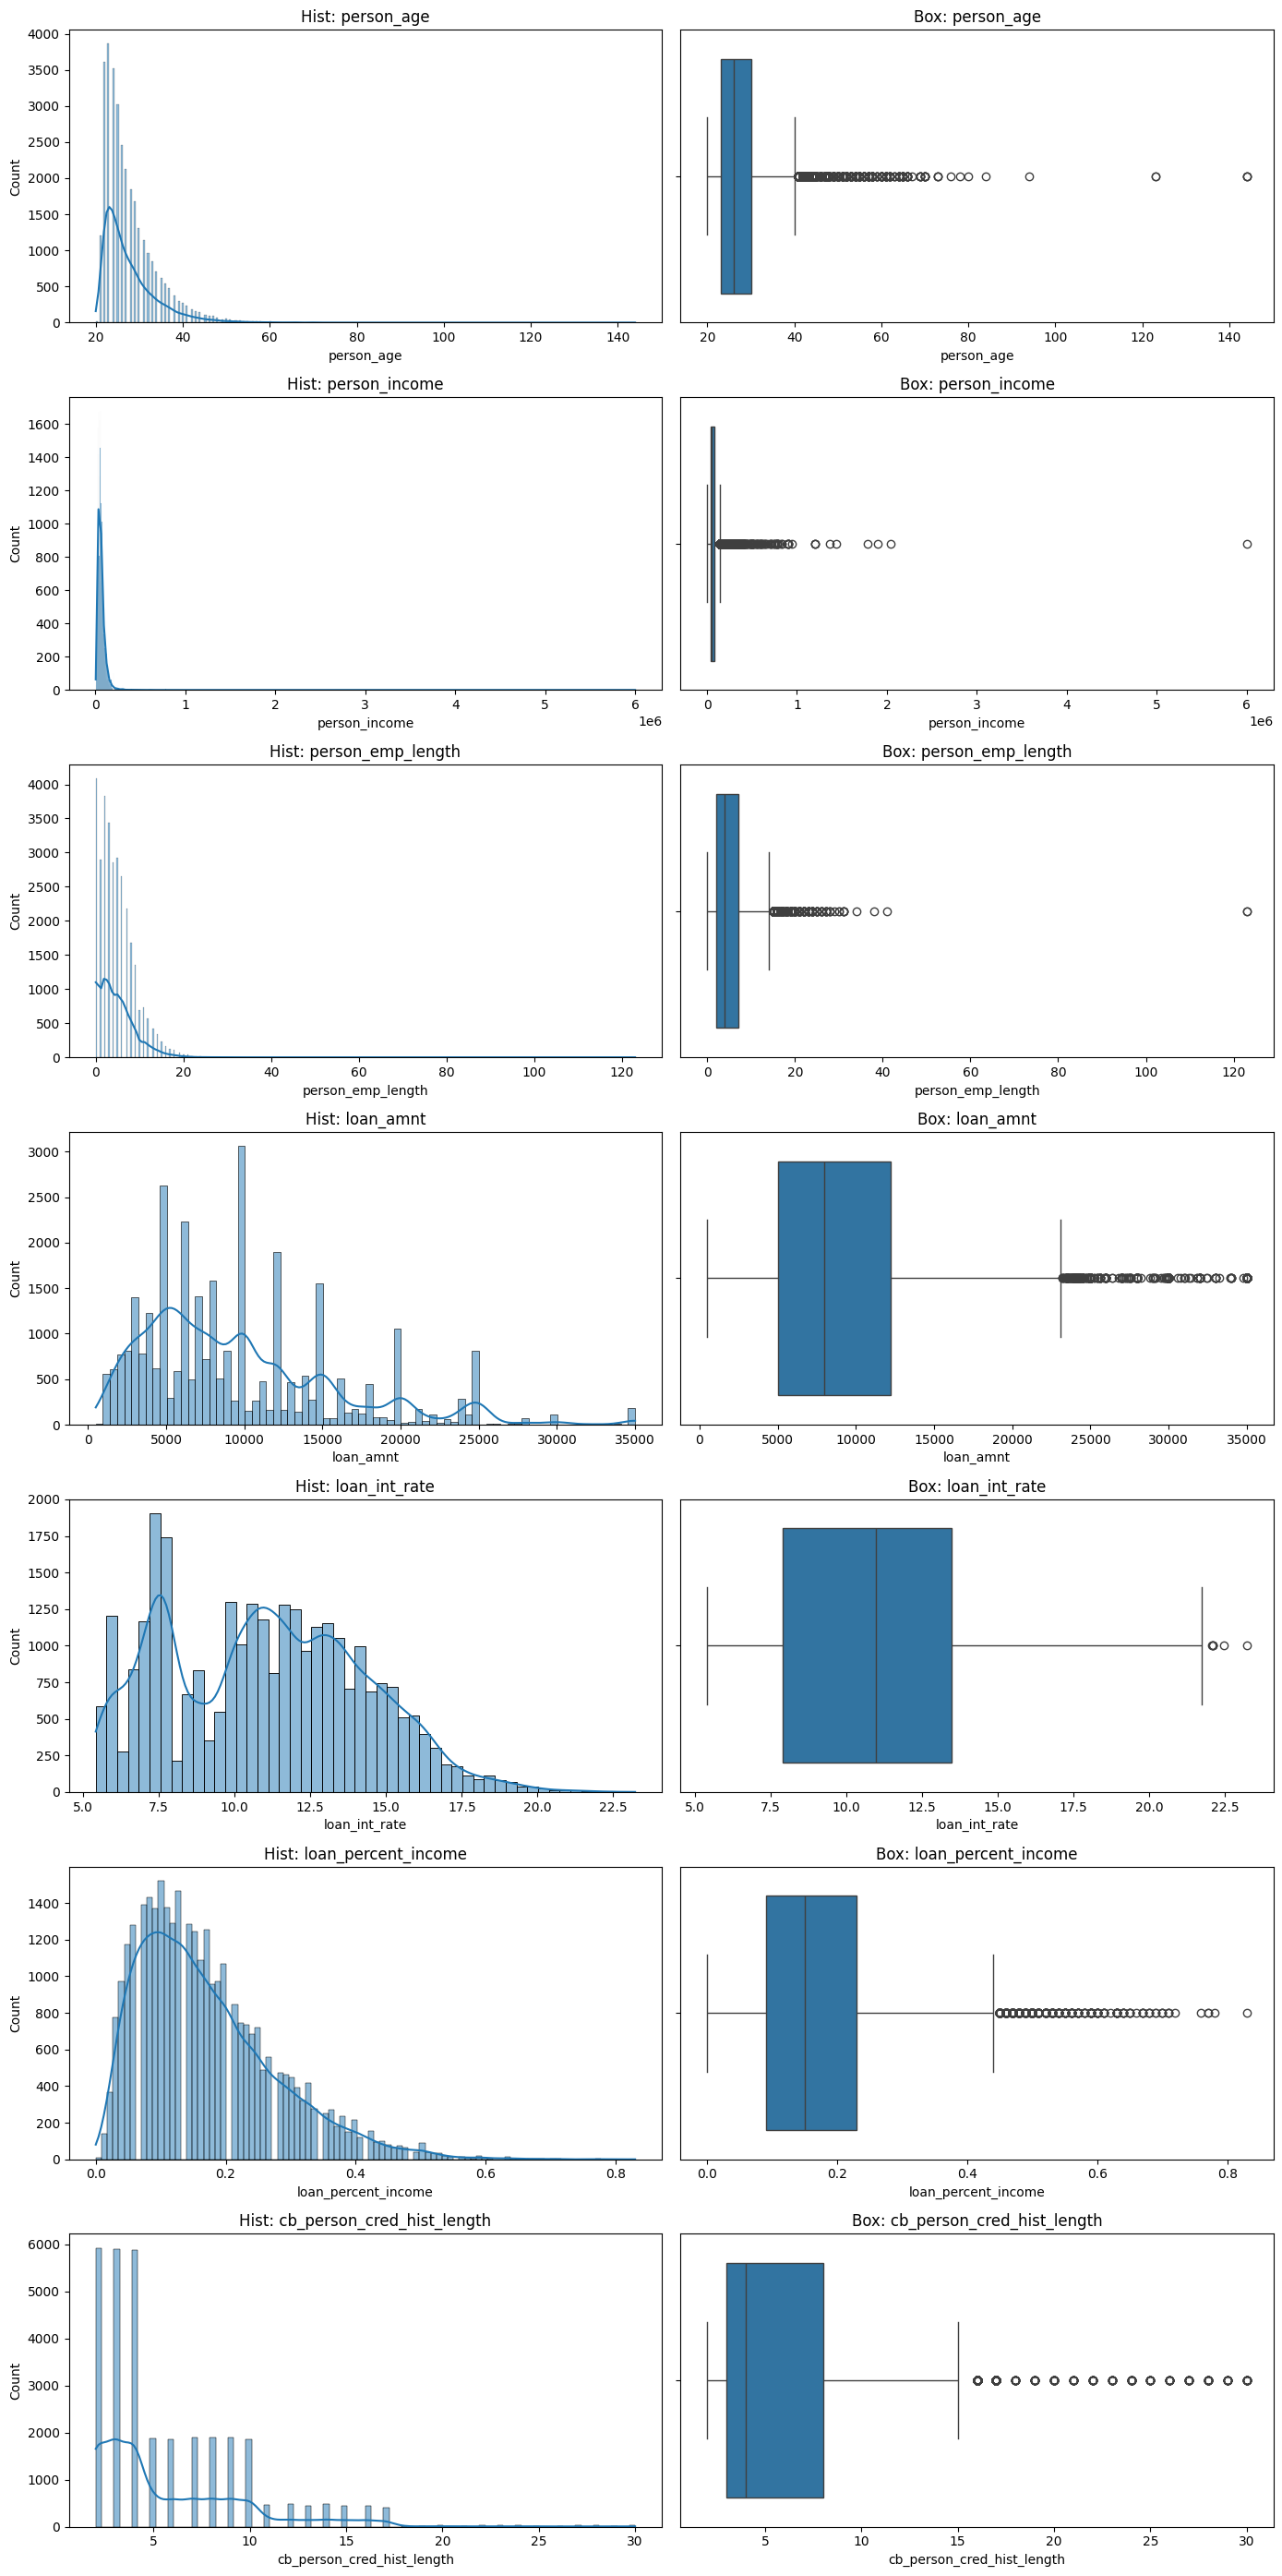

In [22]:
n_plot = min(8, len(Kolumny_numeryczne))
plt.figure(figsize=(14, 4*n_plot))
for i, c in enumerate(Kolumny_numeryczne[:n_plot], 1):
    plt.subplot(n_plot, 2, 2*i-1)
    sns.histplot(data[c].dropna(), kde=True)
    plt.title(f"Hist: {c}")
    plt.subplot(n_plot, 2, 2*i)
    sns.boxplot(x=data[c])
    plt.title(f"Box: {c}")
plt.tight_layout()
plt.show()

In [23]:
from scipy.stats import shapiro

for col in Kolumny_numeryczne:
    stat, p = shapiro(data[col])
    print(col, "p-value:", p)

person_age p-value: 9.693875593707927e-104
person_income p-value: 1.727941254101503e-133
person_emp_length p-value: nan
loan_amnt p-value: 1.2400162474275111e-85
loan_int_rate p-value: nan
loan_percent_income p-value: 9.639795589672289e-80
cb_person_cred_hist_length p-value: 6.677171977900456e-101


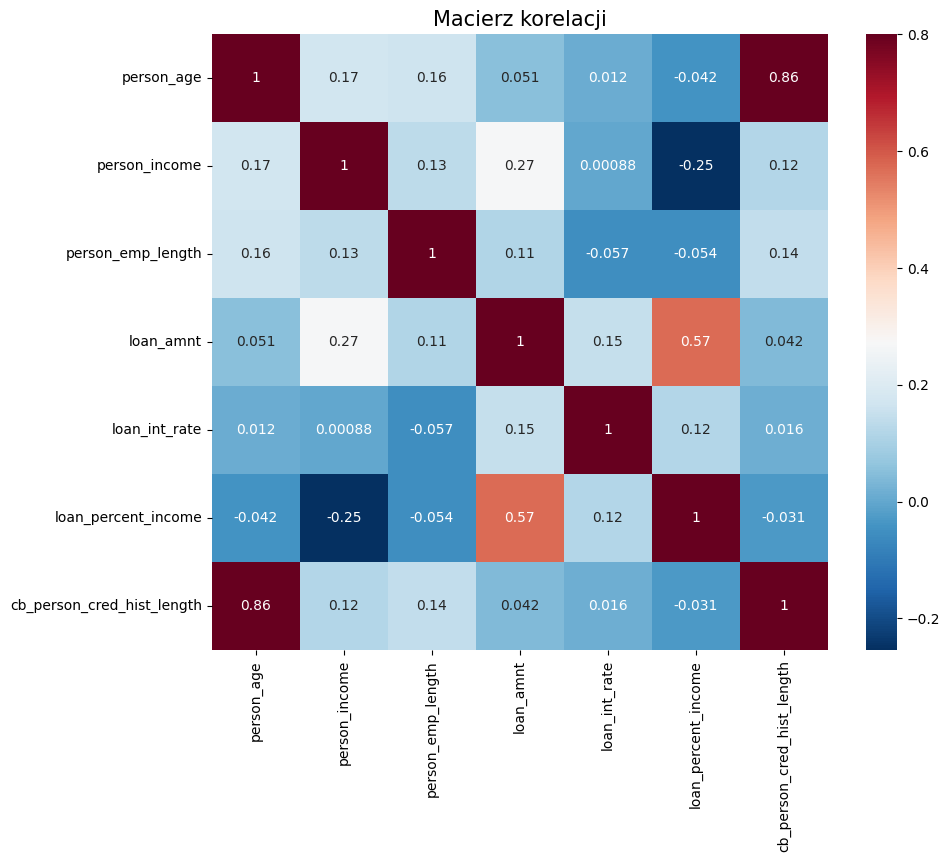

In [24]:
corr = data[Kolumny_numeryczne].corr(method = "pearson")
plt.figure(figsize=(10,8))
sns.heatmap(data[Kolumny_numeryczne].corr(method="pearson"), vmax =.8, square = True, annot = True,cmap='RdBu_r' )
plt.title('Macierz korelacji',fontsize=15)
plt.show()

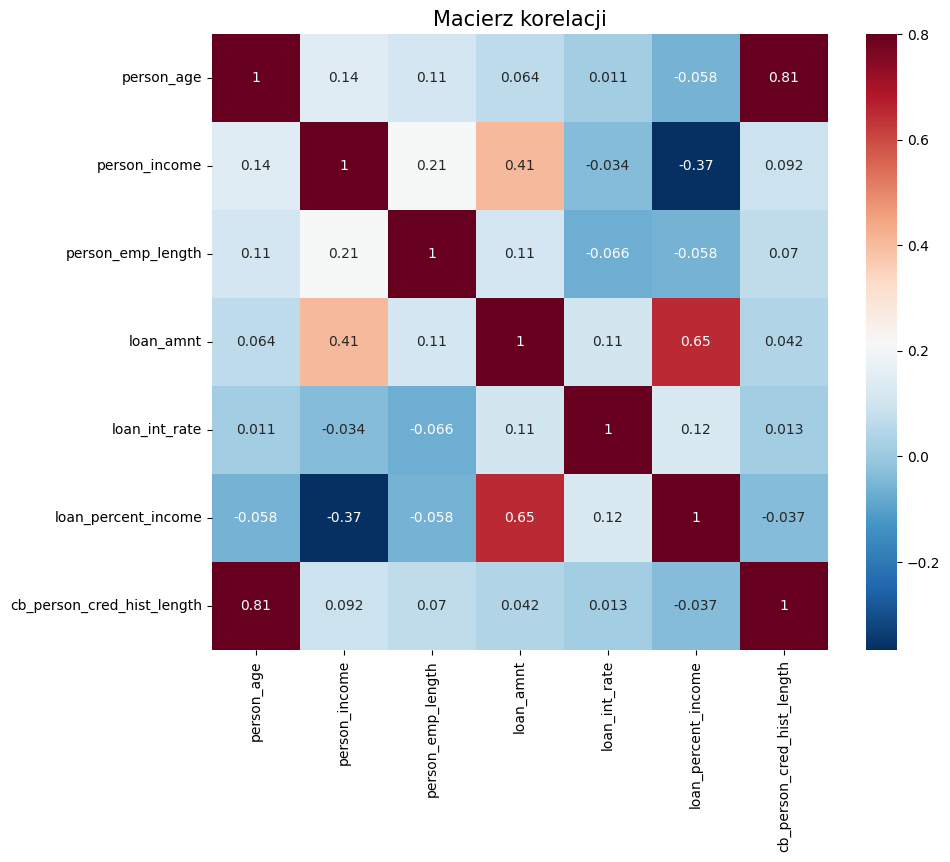

In [25]:
corr_spearman = data[Kolumny_numeryczne].corr(method = "spearman")
plt.figure(figsize=(10,8))
sns.heatmap(data[Kolumny_numeryczne].corr(method = "spearman"), vmax =.8, square = True, annot = True,cmap='RdBu_r' )
plt.title('Macierz korelacji',fontsize=15)
plt.show()

## Missingi

In [26]:
#Wyliczam procentowy udział missingów - pokazuje cechy dla których występują missingi
udzial=((data.isnull()).sum())/((~data.isnull()).sum()+(data.isnull()).sum())
udzial_oczyszcz=round(udzial[udzial>0],2)*100

#wyliczam liczbę misingów
ilosc_oczyszcz=data.isnull().sum()[data.isnull().sum()>0]
podsumowanie=pd.concat([ilosc_oczyszcz,udzial_oczyszcz],axis=1)
podsumowanie.columns=["Ilość missingów","% udział missingów"]
podsumowanie

,Ilość missingów,% udział missingów
person_emp_length,887,3.0
loan_int_rate,3095,10.0


In [27]:
Nan_per = data.isnull().sum()/data.shape[0]*100
Nan_per.round(2)
# person_emp_length zawiera 2,75% null
# loan_int_rate zawiera 9,56% wartości null

person_age                    0.00
person_income                 0.00
person_home_ownership         0.00
person_emp_length             2.74
loan_intent                   0.00
loan_grade                    0.00
loan_amnt                     0.00
loan_int_rate                 9.55
loan_status                   0.00
loan_percent_income           0.00
cb_person_default_on_file     0.00
cb_person_cred_hist_length    0.00
dtype: float64

In [28]:
print('person_emp_length mode {}'.format(data['person_emp_length'].mode()[0]))
print('person_emp_length median {}'.format(data['person_emp_length'].median()))
print('loan_int_rate mode {}'.format(data['loan_int_rate'].mode()[0]))
print('loan_int_rate median {}'.format(data['loan_int_rate'].median()))

person_emp_length mode 0.0
person_emp_length median 4.0
loan_int_rate mode 7.51
loan_int_rate median 10.99


In [29]:
missing_rows1 = data[data['person_emp_length'].isnull()]
missing_rows2 = data[data['loan_int_rate'].isnull()]
print(missing_rows1, missing_rows2)

       person_age  person_income person_home_ownership  person_emp_length  \
105            22          12600              MORTGAGE                NaN   
222            24         185000              MORTGAGE                NaN   
379            24          16800              MORTGAGE                NaN   
407            25          52000                  RENT                NaN   
408            22          17352              MORTGAGE                NaN   
...           ...            ...                   ...                ...   
32285          38          12000                   OWN                NaN   
32328          51          18408                  RENT                NaN   
32360          70          39996                  RENT                NaN   
32453          56          32400                  RENT                NaN   
32471          53          54000                  RENT                NaN   

             loan_intent loan_grade  loan_amnt  loan_int_rate  loan_status 

In [30]:
def fill_and_evaluate(data, fill_emp_length, fill_loan_int_rate, features, target):
    df_copy = data.copy()
    df_copy['person_emp_length'] = df_copy['person_emp_length'].fillna(fill_emp_length)
    df_copy['loan_int_rate'] = df_copy['loan_int_rate'].fillna(fill_loan_int_rate)
    
    X = df_copy[features]
    y = df_copy[target]
    
    #model = XGBClassifier(learning_rate = 0.1,n_estimators = 100, max_depth = 3)
    model = LogisticRegression(max_iter = 1000)
    scores = cross_val_score(model, X, y, cv=5, scoring='roc_auc')
    
    print(f"Uzupełnienie: emp_length={fill_emp_length}, loan_int_rate={fill_loan_int_rate} -> Mean AUC: {np.mean(scores):.4f}")

# Przykładowe wywołania
fill_and_evaluate(data, 0.0, 7.51, Kolumny_numeryczne, target)  # moda i moda
fill_and_evaluate(data, 0.0, 10.99, Kolumny_numeryczne, target) # moda i mediana
fill_and_evaluate(data, 4.0, 7.51, Kolumny_numeryczne, target)  # mediana i moda
fill_and_evaluate(data, 4.0, 10.99, Kolumny_numeryczne, target) # mediana i mediana

Uzupełnienie: emp_length=0.0, loan_int_rate=7.51 -> Mean AUC: 0.8144
Uzupełnienie: emp_length=0.0, loan_int_rate=10.99 -> Mean AUC: 0.8225
Uzupełnienie: emp_length=4.0, loan_int_rate=7.51 -> Mean AUC: 0.8143
Uzupełnienie: emp_length=4.0, loan_int_rate=10.99 -> Mean AUC: 0.8221


In [31]:
# Uzupełnienie person_emp_length medianą (4.0) - bardziej odporna na outliery
mode_emp_length = 4.0
data['person_emp_length'] = data['person_emp_length'].fillna(mode_emp_length)

# Uzupełnienie loan_int_rate medianą (10.99) - bezpieczniejsze
median_loan_int_rate = 10.99
data['loan_int_rate'] = data['loan_int_rate'].fillna(median_loan_int_rate)

# Sprawdzenie czy są jeszcze missingi
print(data[['person_emp_length', 'loan_int_rate']].isnull().sum())

person_emp_length    0
loan_int_rate        0
dtype: int64


## Analiza outliers

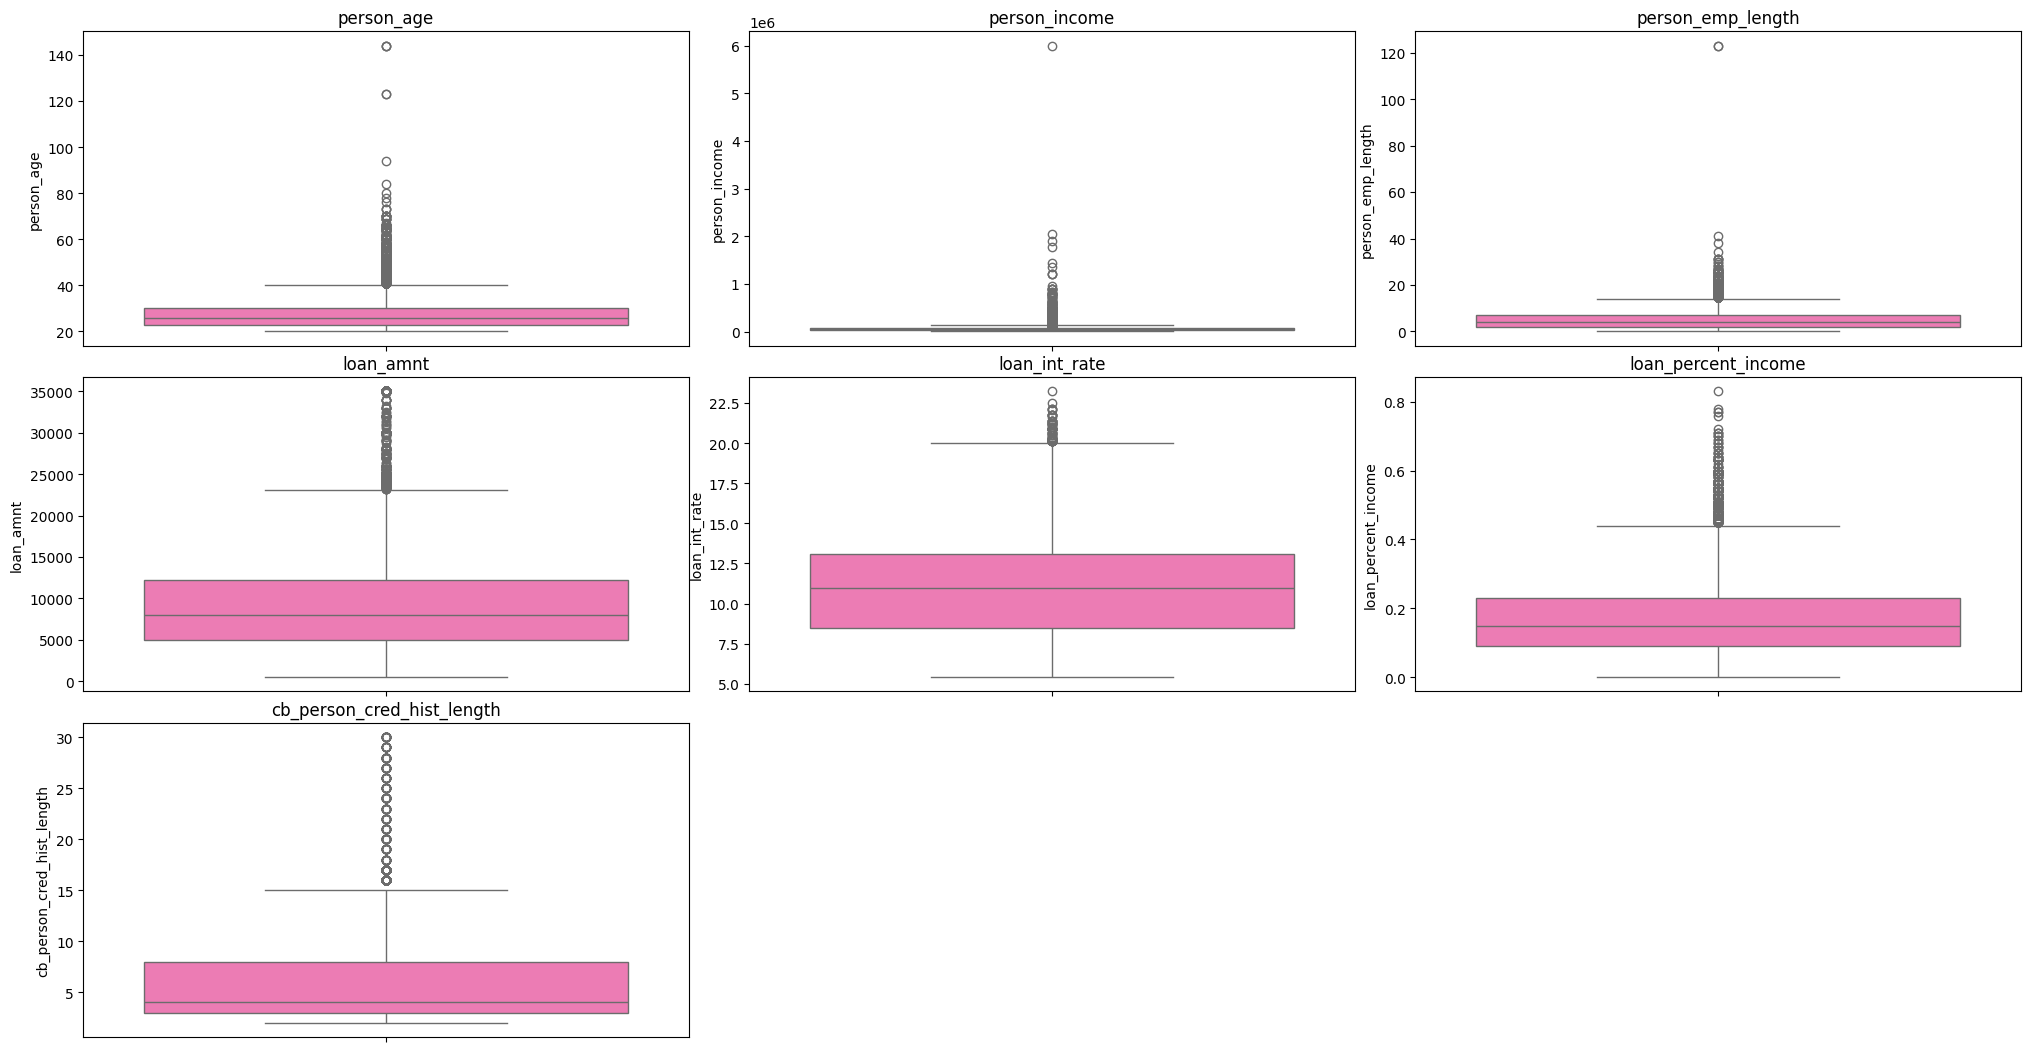

In [32]:
fig = plt.figure(figsize=(25,40))
for i , cecha in enumerate(Kolumny_numeryczne):
    ax = fig.add_subplot(9,3,i+1)
    ax.set_title(cecha)
    sns.boxplot(data= data[cecha], ax=ax,color ='#FF69B4')
plt.subplots_adjust(hspace = 0.1, wspace = 0.1)
plt.show()

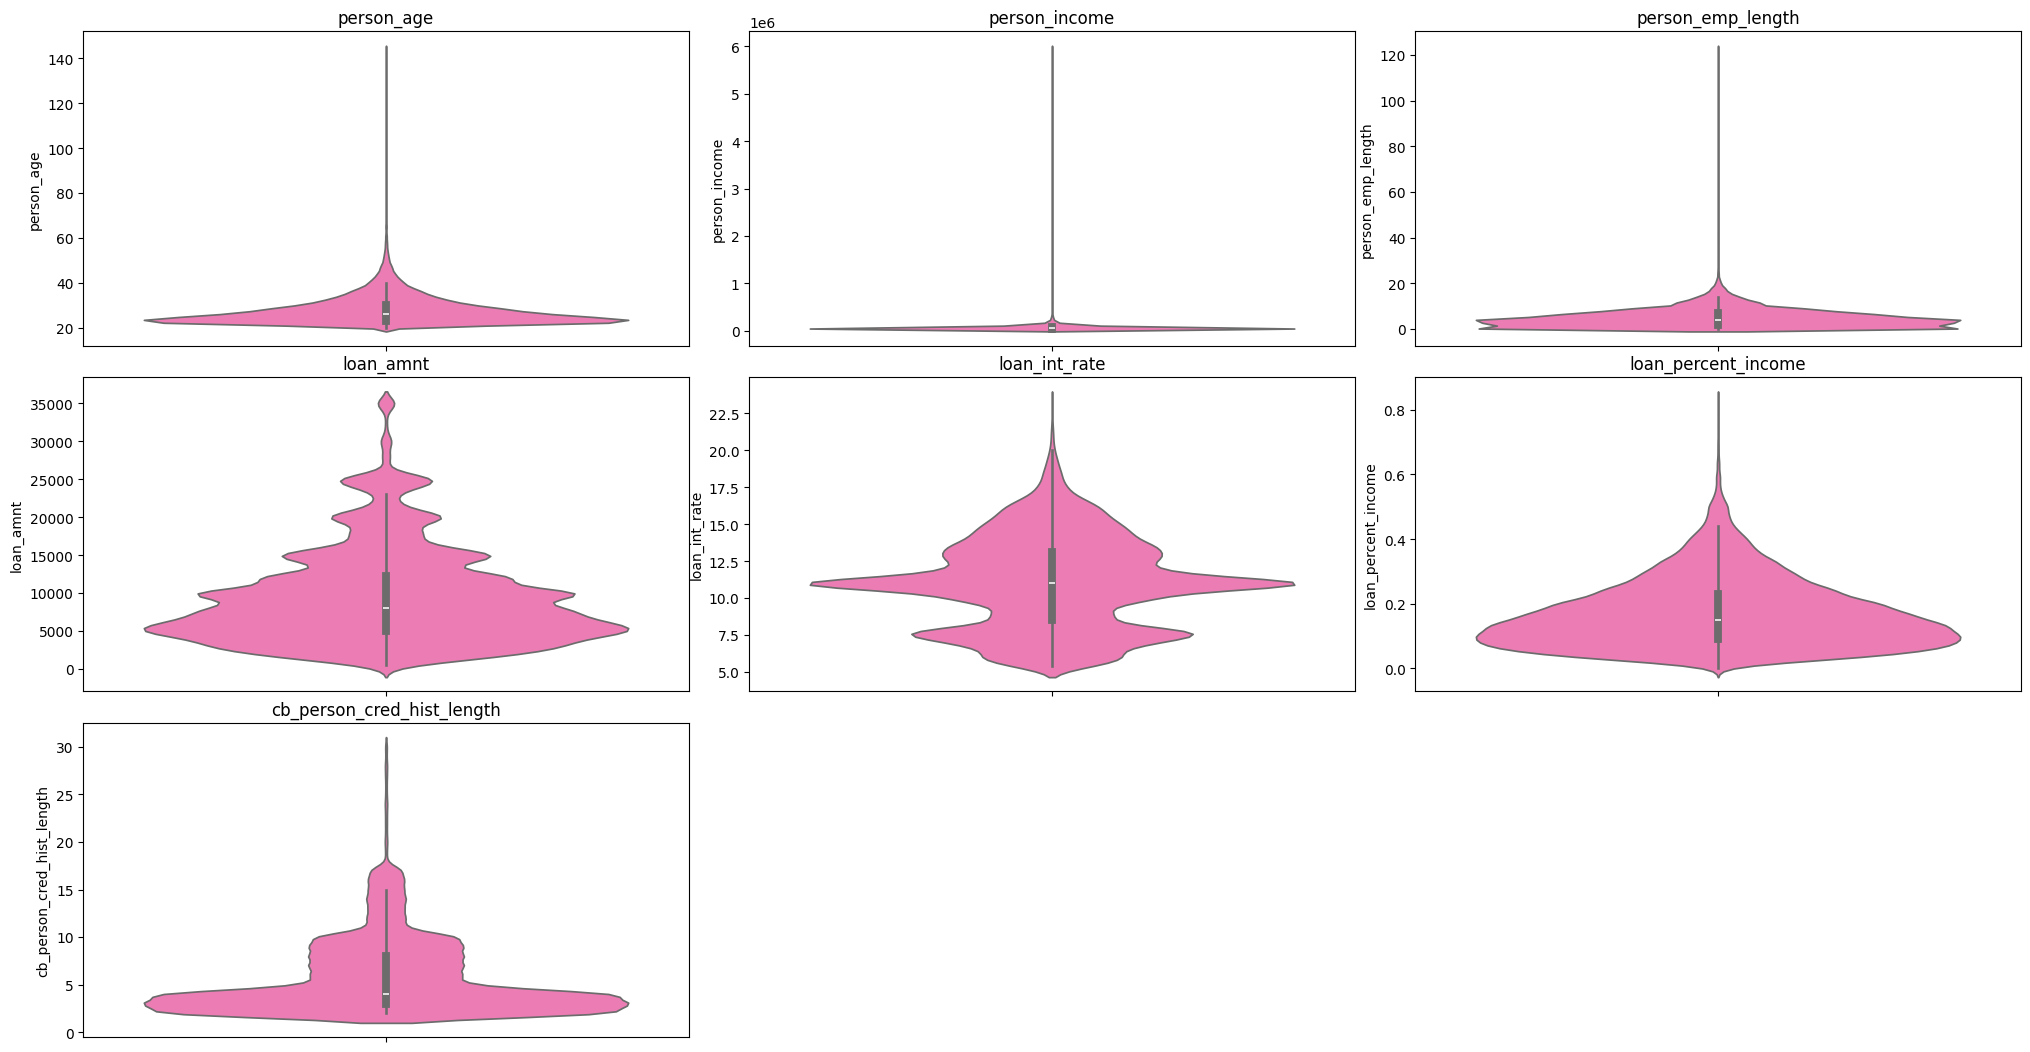

In [33]:
fig = plt.figure(figsize=(25,40))
for i , cecha in enumerate(Kolumny_numeryczne):
    ax = fig.add_subplot(9,3,i+1)
    ax.set_title(cecha)
    sns.violinplot(data=data[cecha], ax=ax, color ='#FF69B4')
plt.subplots_adjust(hspace = 0.1, wspace = 0.1)
plt.show()

In [34]:
#Przygotowanie odpowiednich list
indeks=[]
ilosc=[]
srednia=[]
odchylenie=[]
minimum=[]
maximum=[]
kwartyl1=[]
mediana=[]
kwartyl3=[]
ilosc_out=[]
udzial_out=[]
ilosc_out_z=[]
udzial_out_z=[]

#Pętla wyliczająca podstawowe informacje
for cecha in Kolumny_numeryczne:
    indeks.append(cecha)
    ilosc.append(data[cecha].count())
    srednia.append(data[cecha].mean())
    odchylenie.append(data[cecha].std())
    minimum.append(data[cecha].min())
    maximum.append(data[cecha].max())
    kwar1=data[cecha].quantile(0.25)
    kwar3=data[cecha].quantile(0.75)
    kwartyl1.append(kwar1)
    mediana.append(data[cecha].quantile(0.50))
    kwartyl3.append(kwar3)
    iqr=kwar3-kwar1
    ilosc_out.append(sum(data[cecha]>kwar3+1.5*iqr)+sum(data[cecha]<kwar1-1.5*iqr))
    udzial_out.append((sum(data[cecha]>kwar3+1.5*iqr)+sum(data[cecha]<kwar1-1.5*iqr))/(data[cecha].count())*100)
    out_z_score = (sum(((data[cecha]-data[cecha].mean())/(data[cecha].std()))>3)+
                      sum(((data[cecha]-data[cecha].mean())/(data[cecha].std()))<-3))
    ilosc_out_z.append(out_z_score)
    udzial_out_z.append(out_z_score/(data[cecha].count())*100)
#Finalna tablica
tabela=pd.DataFrame({'Ilość':ilosc,"Średnia":srednia,"Odchylenie":odchylenie,"Minimum":minimum,"Maksimum":maximum,
                    "I kwartyl":kwartyl1,"Mediana":mediana,"III kwartyl":kwartyl3, "Outliers rozstęp":ilosc_out,
                     "Outliers Z-score":ilosc_out_z, "% outliersów ":udzial_out, "% outliersów Z-score":udzial_out_z},index=indeks)

tabela

,Ilość,Średnia,Odchylenie,Minimum,Maksimum,I kwartyl,Mediana,III kwartyl,Outliers rozstęp,Outliers Z-score,% outliersów,% outliersów Z-score
person_age,32416,27.747008,6.354100,20.00,144.00,23.00,26.00,30.00,1491,557,4.599580,1.718287
person_income,32416,66091.640826,62015.580269,4000.00,6000000.00,38542.00,55000.00,79218.00,1478,232,4.559477,0.715696
person_emp_length,32416,4.768880,4.090411,0.00,123.00,2.00,4.00,7.00,852,321,2.628332,0.990252
loan_amnt,32416,9593.845632,6322.730241,500.00,35000.00,5000.00,8000.00,12250.00,1679,336,5.179541,1.036525
loan_int_rate,32416,11.014662,3.083050,5.42,23.22,8.49,10.99,13.11,70,51,0.215943,0.157330
loan_percent_income,32416,0.170250,0.106812,0.00,0.83,0.09,0.15,0.23,650,335,2.005183,1.033440
cb_person_cred_hist_length,32416,5.811297,4.059030,2.00,30.00,3.00,4.00,8.00,1139,284,3.513697,0.876111


## Strategia outliers

In [35]:
for col in Kolumny_numeryczne:
    q_low = data[col].quantile(0.01)
    q_high = data[col].quantile(0.99)
    print(f"{col}: 1% = {q_low}, 99% = {q_high}")

person_age: 1% = 21.0, 99% = 50.0
person_income: 1% = 14400.0, 99% = 225000.0
person_emp_length: 1% = 0.0, 99% = 17.0
loan_amnt: 1% = 1000.0, 99% = 29800.0
loan_int_rate: 1% = 5.42, 99% = 18.39
loan_percent_income: 1% = 0.02, 99% = 0.5
cb_person_cred_hist_length: 1% = 2.0, 99% = 17.0


In [36]:
# Funkcja do winsoryzacji
def winsorize_df(data, Kolumny_numeryczne, lower_pct=0.01, upper_pct=0.99):
    df_w = data.copy()
    for col in Kolumny_numeryczne:
        lower = df_w[col].quantile(lower_pct)
        upper = df_w[col].quantile(upper_pct)
        df_w[col] = np.clip(df_w[col], lower, upper)
    return df_w

# Funkcja do usuwania outlierów
def drop_outlier_rows(data, Kolumny_numeryczne, method='iqr', k=1.5):
    df_clean = data.copy()
    initial_rows = df_clean.shape[0]

    for col in Kolumny_numeryczne:
        if method == 'iqr':
            Q1 = df_clean[col].quantile(0.25)
            Q3 = df_clean[col].quantile(0.75)
            IQR = Q3 - Q1
            lower = Q1 - k * IQR
            upper = Q3 + k * IQR
            df_clean = df_clean[(df_clean[col] >= lower) & (df_clean[col] <= upper)]

    n_dropped = initial_rows - df_clean.shape[0]
    return df_clean, n_dropped

# Funkcja do ewaluacji strategii
def evaluate_outlier_strategy(data, features, target, strategies=['none', 'winsorize', 'drop']):
    results = {}

    for strategy in strategies:
        if strategy == 'winsorize':
            data_proc = winsorize_df(data, features, lower_pct=0.01, upper_pct=0.99)
            print("Winsoryzacja 1%-99% zastosowana.")
        elif strategy == 'drop':
            data_proc, dropped = drop_outlier_rows(data, features, method='iqr', k=1.5)
            print(f"Usunięto {dropped} wierszy (IQR k=1.5). Nowy rozmiar:", data_proc.shape)
        else:
            data_proc = data.copy()
            print("Outliers pozostawione bez zmian.")
        
        X_proc = data_proc[features]
        y_proc = data_proc[target]
        
        model = RandomForestClassifier(n_estimators=100, random_state=42)
        scores = cross_val_score(model, X_proc, y_proc, cv=5, scoring='roc_auc')
        #model = XGBClassifier(use_label_encoder=False, eval_metric='logloss')
        #scores = cross_val_score(model, X_proc, y_proc, cv=5, scoring='roc_auc')
        #model = LogisticRegression(max_iter=1000)
        #scores = cross_val_score(model, X_proc, y_proc, cv=5, scoring='roc_auc')
        results[strategy] = np.mean(scores)
        print(f"Strategia: {strategy}, Średni wynik AUC: {results[strategy]:.4f}")
    
    best_strategy = max(results, key=results.get)
    print(f"\nNajlepsza strategia eliminacji outlierów: {best_strategy} z wynikiem AUC {results[best_strategy]:.4f}")
    
    # Zwracamy dane z przetworzoną najlepszą metodą
    if best_strategy == 'winsorize':
        return winsorize_df(data, features, lower_pct=0.01, upper_pct=0.99)
    elif best_strategy == 'drop':
        data_proc, _ = drop_outlier_rows(data, features, method='iqr', k=1.5)
        return data_proc
    else:
        return data.copy()

# Uruchomienie funkcji - ze względu na to że z pośród trzech testowanych modeli AUC było najlepsze przy strategii drop, użyjemy jej
data_proc = evaluate_outlier_strategy(data, Kolumny_numeryczne, target)


Outliers pozostawione bez zmian.
Strategia: none, Średni wynik AUC: 0.8336
Winsoryzacja 1%-99% zastosowana.
Strategia: winsorize, Średni wynik AUC: 0.8348
Usunięto 6410 wierszy (IQR k=1.5). Nowy rozmiar: (26006, 12)
Strategia: drop, Średni wynik AUC: 0.8401

Najlepsza strategia eliminacji outlierów: drop z wynikiem AUC 0.8401


## Test czy wszystko zostało oczyszczone

In [37]:
print("Rozmiar danych przed:", data.shape)
print("Rozmiar danych po:", data_proc.shape)

Rozmiar danych przed: (32416, 12)
Rozmiar danych po: (26006, 12)


In [38]:
print(data_proc.isnull().sum())

person_age                    0
person_income                 0
person_home_ownership         0
person_emp_length             0
loan_intent                   0
loan_grade                    0
loan_amnt                     0
loan_int_rate                 0
loan_status                   0
loan_percent_income           0
cb_person_default_on_file     0
cb_person_cred_hist_length    0
dtype: int64


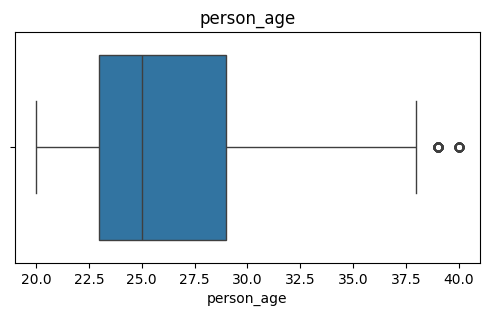

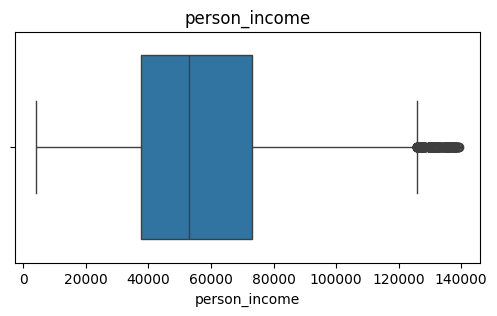

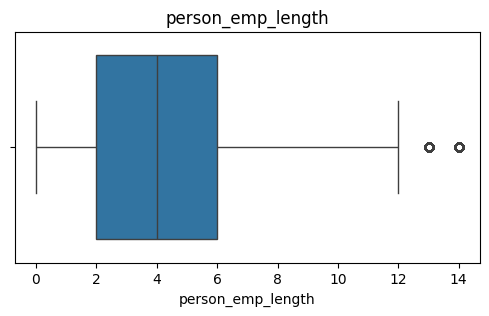

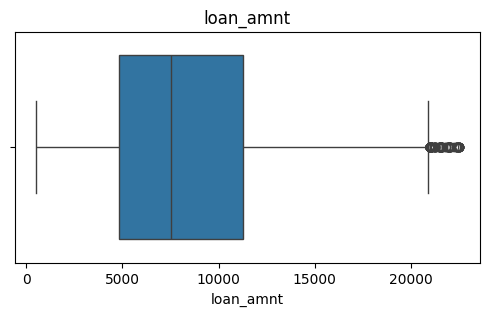

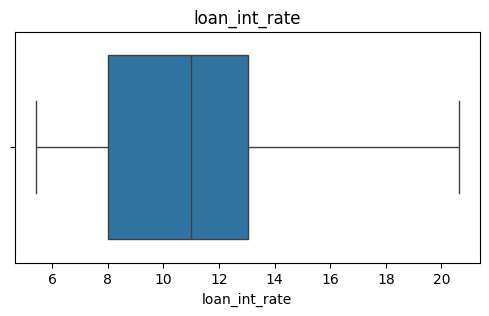

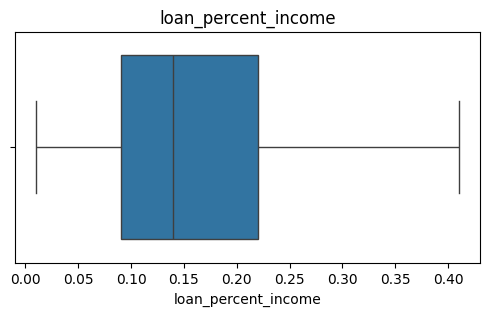

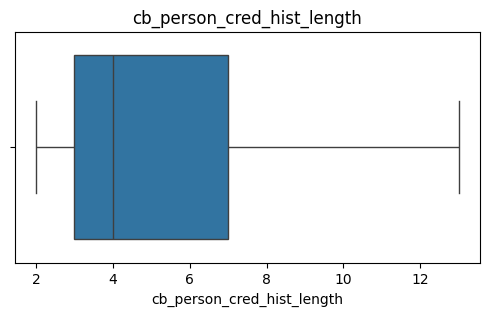

In [39]:
for col in Kolumny_numeryczne:
    plt.figure(figsize=(6,3))
    sns.boxplot(x=data_proc[col])
    plt.title(col)
    plt.show()

In [40]:
data_proc[Kolumny_numeryczne].describe().round(2)

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length
count,26006.00,26006.00,26006.00,26006.00,26006.00,26006.00,26006.00
mean,26.18,57461.02,4.34,8332.69,10.91,0.16,4.83
std,3.97,26288.68,3.32,4810.39,3.04,0.09,2.71
min,20.00,4080.00,0.00,500.00,5.42,0.01,2.00
25%,23.00,37800.00,2.00,4800.00,8.00,0.09,3.00
50%,25.00,53000.00,4.00,7500.00,10.99,0.14,4.00
75%,29.00,73000.00,6.00,11250.00,13.06,0.22,7.00
max,40.00,139200.00,14.00,22500.00,20.62,0.41,13.00


In [41]:
cv = (data_proc[Kolumny_numeryczne].std() / data_proc[Kolumny_numeryczne].mean())

In [42]:
cv*100

person_age                    15.174606
person_income                 45.750451
person_emp_length             76.473278
loan_amnt                     57.729104
loan_int_rate                 27.824082
loan_percent_income           56.044020
cb_person_cred_hist_length    56.099236
dtype: float64

In [43]:
def count_outliers(df, cols, k=1.5):
    outlier_counts = {}
    for col in cols:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower = Q1 - k*IQR
        upper = Q3 + k*IQR
        outliers = df[(df[col] < lower) | (df[col] > upper)]
        outlier_counts[col] = outliers.shape[0]
    return outlier_counts

count_outliers(data_proc, Kolumny_numeryczne)

{'person_age': 179,
 'person_income': 352,
 'person_emp_length': 524,
 'loan_amnt': 221,
 'loan_int_rate': 0,
 'loan_percent_income': 0,
 'cb_person_cred_hist_length': 0}

In [44]:
for col in Kolumny_numeryczne:
    print(col)
    print(data_proc[col].sort_values(ascending=False).head(10))
#dane wyglądają na realistyczne więc nie widzę potrzeby ich usuwać

person_age
30641    40
32029    40
29821    40
30541    40
30545    40
31442    40
29777    40
32007    40
29760    40
29751    40
Name: person_age, dtype: int64
person_income
27407    139200
28000    139008
27406    139008
27404    138996
27403    138600
15468    138000
27396    138000
27399    138000
27401    138000
31821    138000
Name: person_income, dtype: int64
person_emp_length
25517    14.0
30099    14.0
22610    14.0
30010    14.0
25853    14.0
19846    14.0
18922    14.0
25859    14.0
22581    14.0
22541    14.0
Name: person_emp_length, dtype: float64
loan_amnt
13454    22500
26121    22500
30482    22500
25950    22500
488      22500
490      22500
17433    22500
14724    22400
26661    22400
18282    22400
Name: loan_amnt, dtype: int64
loan_int_rate
7573     20.62
13364    20.62
10237    20.62
22911    20.52
12227    20.48
19246    20.30
7637     20.30
2620     20.30
26998    20.25
12644    20.25
Name: loan_int_rate, dtype: float64
loan_percent_income
8070     0.41
3186    

In [45]:
data_proc.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
5,21,9900,OWN,2.0,VENTURE,A,2500,7.14,1,0.25,N,2
9,21,10000,OWN,6.0,VENTURE,D,1600,14.74,1,0.16,N,3
19,24,10800,MORTGAGE,8.0,EDUCATION,B,1750,10.99,1,0.16,N,2
23,24,10980,OWN,0.0,PERSONAL,A,1500,7.29,0,0.14,N,3


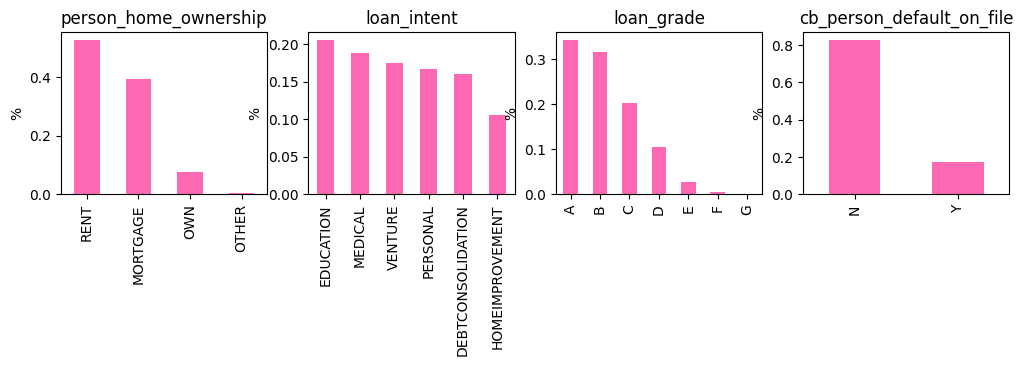

In [46]:
fig = plt.figure(figsize=(25,40))
for i , cecha in enumerate(Kolumny_tekstowe):
    ax = fig.add_subplot(10,8,i+1)
    ax.set_title(cecha)
    (data_proc[cecha].value_counts()/len(data_proc[cecha])).plot.bar(color ='#FF69B4')
    ax.set(ylabel="%", xlabel= "")  
plt.subplots_adjust(hspace = 1, wspace = 0.2)
plt.show()

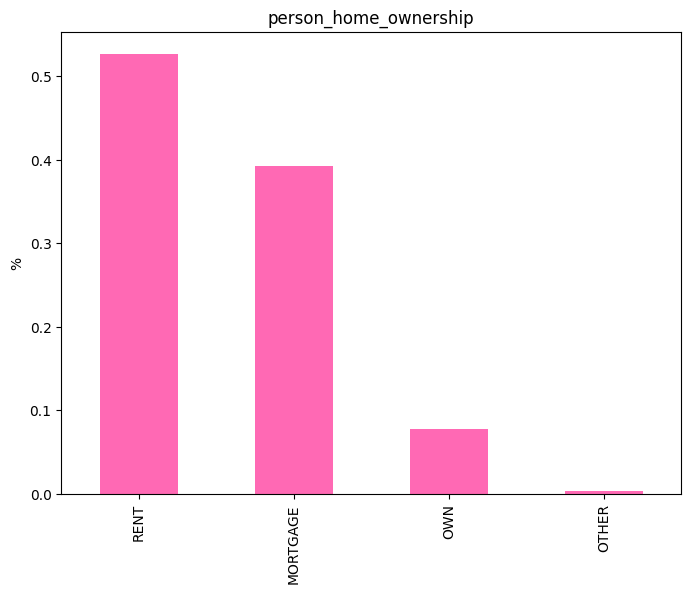

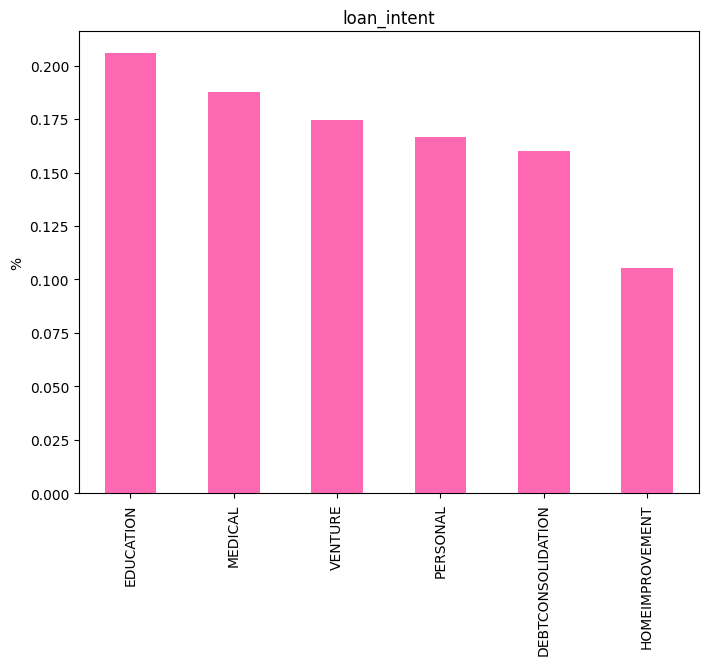

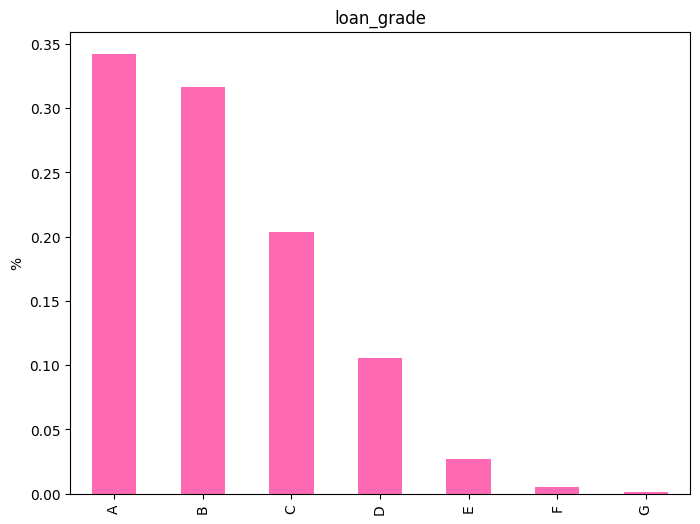

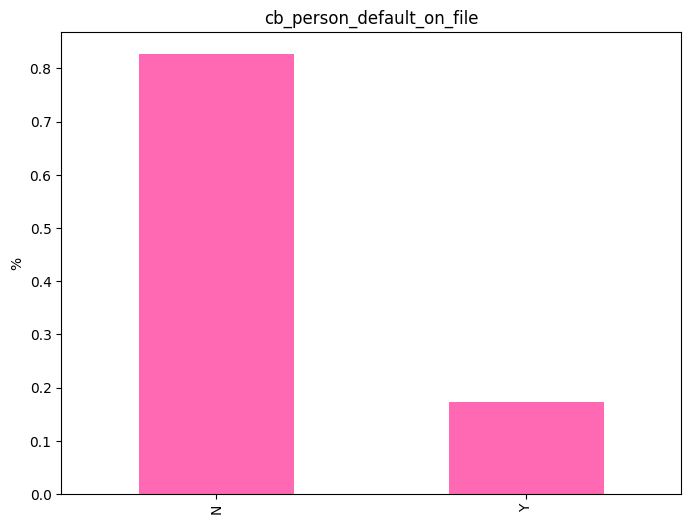

In [47]:
for cecha in Kolumny_tekstowe:
    plt.figure(figsize=(8,6))  # tworzymy nową figurę dla każdej zmiennej
    (data_proc[cecha].value_counts() / len(data_proc[cecha])).plot.bar(color='#FF69B4')
    plt.title(cecha)
    plt.ylabel("%")
    plt.xlabel("")
    plt.show()

In [31]:
import plotly.express as px

custom_pink = ['#FFB6C1','#FF69B4','#FF1493','#C71585','#FFE6F2', '#FF85A1', '#E75480']

mapowanie_wlasnosc = {
    "RENT": "Wynajem",
    "OWN": "Własność",
    "MORTGAGE": "Kredyt hipoteczny",
    "OTHER": "Inne"
}

wlasnosc = (
    data_proc['person_home_ownership']
    .map(mapowanie_wlasnosc)
    .value_counts()
)

fig = px.pie(
    values=wlasnosc.values,
    names=wlasnosc.index,
    color_discrete_sequence=custom_pink
)

fig.update_traces(
    textinfo='percent+label',  # możesz zmienić na 'label' jeśli nie chcesz procentów w ogóle
    textfont=dict(size=10, family="Times New Roman"),
    marker=dict(line=dict(color='white', width=1))
)

fig.update_layout(
    width=500,
    height=500,
    template="simple_white",
    font=dict(
        family="Times New Roman",
        size=10
    ),
    legend=dict(
        title="Forma zamieszkania",
        font=dict(size=10),
        orientation="h",
        y=-0.1
    )
)

fig.show()

In [ ]:
# słownik tłumaczeń
mapowanie_loan_intent = {
    "EDUCATION": "Edukacja",
    "MEDICAL": "Cele medyczne",
    "VENTURE": "Działalność gospodarcza",
    "PERSONAL": "Cele osobiste",
    "DEBTCONSOLIDATION": "Konsolidacja zadłużenia",
    "HOMEIMPROVEMENT": "Remont mieszkania"
}

udzialy = (
    data_proc['loan_intent']
    .map(mapowanie_loan_intent)
    .value_counts(normalize=True)
    .sort_values(ascending=False)
)

fig = px.bar(
    x=udzialy.index,
    y=udzialy.values * 100,
    text=[f"{v*100:.2f}%" for v in udzialy.values],
    template='presentation',
    color_discrete_sequence=custom_pink
)

fig.update_traces(
    textfont=dict(size=10, family="Times New Roman")
)

fig.update_layout(
    width=600,
    height=300,
    template="simple_white",
    font=dict(  
        family="Times New Roman",
        size=10
    ),
    title=dict(
        text='Struktura celu kredytu (%)',
        x=0.5,
        xanchor='center',
        font=dict(size=10)
    ),
    xaxis=dict(
        title=dict(text='', font=dict(size=10)),
        tickfont=dict(size=10)
    ),
    yaxis=dict(
        title=dict(text='Udział procentowy (%)', font=dict(size=10)),
        tickfont=dict(size=10)
    )
)

fig.show()

In [18]:

counts = (data_proc['loan_grade']
          .value_counts(normalize=True)  
          .sort_values(ascending=False)) 


fig = px.bar(
    x=counts.index,
    y=counts.values * 100,  
    text=[f"{v*100:.2f}%" for v in counts.values],  
    template='presentation',
    title='loan_grade',
    color_discrete_sequence=custom_pink
)

fig.update_layout(
    width=600,
    height=300,
    title=dict(
        text='Klasa kredytu (%)',
        x=0.5,
        xanchor='center',
        font=dict(size=10)),
    font=dict(  
        family="Times New Roman",
        size=10
    ),
    xaxis=dict(
        title=dict(text='', font=dict(size=10)),
        tickfont=dict(size=10)
    ),
    yaxis=dict(
        title=dict(text='Udział procentowy (%)', font=dict(size=10)),
        tickfont=dict(size=10)
    )
    
)

fig.update_traces(textfont_size=10)

fig.show()

In [19]:

counts = (data_proc['cb_person_default_on_file']
          .value_counts(normalize=True)  
          .sort_values(ascending=False)) 


fig = px.bar(
    x=counts.index,
    y=counts.values * 100,  
    text=[f"{v*100:.2f}%" for v in counts.values],  
    template='presentation',
    title='cb_person_default_on_file',
    color_discrete_sequence=custom_pink
)


fig.update_layout(
    width=600,
    height=300,
    title=dict(
        text='Obecność negatywnej historii kredytowej (%)',
        x=0.5,
        xanchor='center',
        font=dict(size=10)),
    font=dict(  
        family="Times New Roman",
        size=10
    ),
    xaxis=dict(
        title=dict(text='', font=dict(size=10)),
        tickfont=dict(size=10)
    ),
    yaxis=dict(
        title=dict(text='Udział procentowy (%)', font=dict(size=10)),
        tickfont=dict(size=10)
    )
)

fig.update_traces(textfont_size=10)

fig.show()


In [147]:

counts = (data_proc['person_home_ownership']
          .value_counts(normalize=True)  
          .sort_values(ascending=False)) 


fig = px.bar(
    x=counts.index,
    y=counts.values * 100,  
    text=[f"{v*100:.2f}%" for v in counts.values],  
    template='presentation',
    title='person_home_ownership',
    color_discrete_sequence=custom_pink
)


fig.update_layout(
    width=600,    
    height=300, 
    title={'text': 'person_home_ownership', 'x': 0.5, 'xanchor': 'center', 'font': {'size': 12}},
    xaxis=dict(title='', titlefont=dict(size=10), tickfont=dict(size=10)),
    yaxis=dict(title='%', titlefont=dict(size=10), tickfont=dict(size=10))
)
fig.update_traces(
    textfont_size=10
)
fig.show()



In [32]:
from scipy.stats import spearmanr

# wybór zmiennych numerycznych
df = data_proc[Kolumny_numeryczne]

# obliczenie korelacji i p-value
corr, pval = spearmanr(df)

# konwersja do DataFrame
corr_df = pd.DataFrame(corr, index=df.columns, columns=df.columns)
pval_df = pd.DataFrame(pval, index=df.columns, columns=df.columns)

# wyświetlenie macierzy p-value
print("Macierz p-value:")
print(pval_df.round(4))

Macierz p-value:
                            person_age  person_income  person_emp_length  \
person_age                       0.000            0.0             0.0000   
person_income                    0.000            0.0             0.0000   
person_emp_length                0.000            0.0             0.0000   
loan_amnt                        0.000            0.0             0.0000   
loan_int_rate                    0.233            0.0             0.0000   
loan_percent_income              0.000            0.0             0.0000   
cb_person_cred_hist_length       0.000            0.0             0.0001   

                            loan_amnt  loan_int_rate  loan_percent_income  \
person_age                     0.0000          0.233               0.0000   
person_income                  0.0000          0.000               0.0000   
person_emp_length              0.0000          0.000               0.0000   
loan_amnt                      0.0000          0.000              

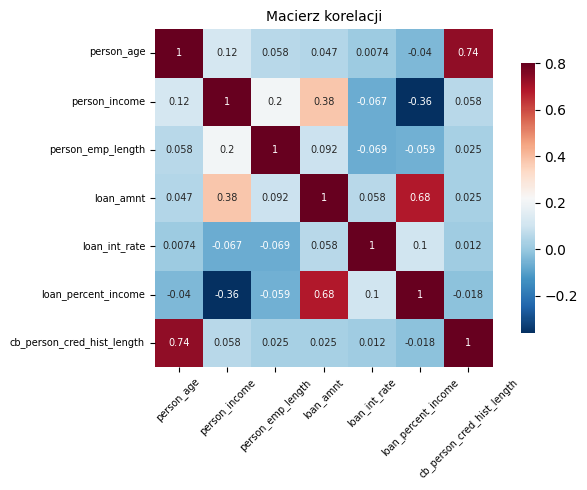

In [48]:
corr = data_proc[Kolumny_numeryczne].corr(method ="spearman")

plt.figure(figsize=(7,5))
ax = sns.heatmap(
    corr,
    vmax=.8,
    square=True,
    annot=True,
    cmap='RdBu_r',
    annot_kws={"size": 7},                 
    cbar_kws={"shrink": 0.8}                
)


ax.set_xticklabels(ax.get_xticklabels(), fontsize=7, rotation=45)
ax.set_yticklabels(ax.get_yticklabels(), fontsize=7)

plt.title('Macierz korelacji', fontsize=10)
plt.tight_layout()
plt.show()


In [35]:
import pandas as pd
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

# Tworzymy podzbiór danych z wybranymi zmiennymi numerycznymi
X = data_proc[Kolumny_numeryczne].copy()

# Dodajemy stałą (potrzebne dla statsmodels)
X_const = add_constant(X)

# Tworzymy DataFrame do przechowania wyników VIF
vif_data = pd.DataFrame()
vif_data['Variable'] = X_const.columns
vif_data['VIF'] = [variance_inflation_factor(X_const.values, i) for i in range(X_const.shape[1])]

# Opcjonalnie usuwamy 'const' z wyników
vif_data = vif_data[vif_data['Variable'] != 'const']

# Wyświetlamy wyniki
print(vif_data)


                     Variable       VIF
1                  person_age  2.636139
2               person_income  4.063031
3           person_emp_length  1.049248
4                   loan_amnt  5.760354
5               loan_int_rate  1.021647
6         loan_percent_income  5.761518
7  cb_person_cred_hist_length  2.624352


In [36]:
import statsmodels.api as sm
import pandas as pd
import numpy as np
from sklearn.utils import resample
from sklearn.model_selection import KFold

# X – dokładnie te same zmienne co przy VIF
lq = data_proc[Kolumny_numeryczne].copy()
lq = sm.add_constant(lq)

# y – ta sama ramka danych co X
zq = data_proc['loan_status']

# Dopasowanie modelu bazowego
model = sm.Logit(zq, lq)
result = model.fit()

print(result.summary())

Optimization terminated successfully.
         Current function value: 0.387117
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:            loan_status   No. Observations:                26006
Model:                          Logit   Df Residuals:                    25998
Method:                           MLE   Df Model:                            7
Date:                Sat, 04 Apr 2026   Pseudo R-squ.:                  0.2329
Time:                        18:38:01   Log-Likelihood:                -10067.
converged:                       True   LL-Null:                       -13125.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                 coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------
const                         -5.8032      0.201    -28.933      0.000      

In [37]:
n_boot = 1000
coefs = []
failed = 0

for i in range(n_boot):
    sample = resample(data_proc)
    
    X_sample = sm.add_constant(sample[Kolumny_numeryczne])
    y_sample = sample['loan_status']
    
    try:
        model_boot = sm.Logit(y_sample, X_sample)
        result_boot = model_boot.fit(disp=0)
        coefs.append(result_boot.params.values)
    except:
        failed += 1
        continue

coefs = np.array(coefs)

coef_means = coefs.mean(axis=0)
coef_std = coefs.std(axis=0)
ci_lower = np.percentile(coefs, 2.5, axis=0)
ci_upper = np.percentile(coefs, 97.5, axis=0)

stability_df = pd.DataFrame({
    "Variable": lq.columns,
    "Original_coef": result.params.values,
    "Bootstrap_mean": coef_means,
    "Std_boot": coef_std,
    "CI_2.5%": ci_lower,
    "CI_97.5%": ci_upper
})

print("Nieudane dopasowania:", failed)
print(stability_df)

Nieudane dopasowania: 0
                     Variable  Original_coef  Bootstrap_mean  Std_boot  \
0                       const      -5.803244       -5.802882  0.216762   
1                  person_age       0.001379        0.001574  0.007214   
2               person_income      -0.000004       -0.000004  0.000002   
3           person_emp_length      -0.022648       -0.022330  0.005881   
4                   loan_amnt      -0.000124       -0.000124  0.000011   
5               loan_int_rate       0.307499        0.307578  0.007010   
6         loan_percent_income      12.475904       12.461459  0.527360   
7  cb_person_cred_hist_length      -0.012282       -0.012556  0.010898   

     CI_2.5%      CI_97.5%  
0  -6.234300 -5.370015e+00  
1  -0.012746  1.499495e-02  
2  -0.000008 -4.663884e-07  
3  -0.034221 -1.128983e-02  
4  -0.000143 -1.026598e-04  
5   0.293630  3.213558e-01  
6  11.459407  1.344904e+01  
7  -0.033879  8.868274e-03  


In [38]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)
coefs_cv = []

for train_idx, test_idx in kf.split(data_proc):
    train = data_proc.iloc[train_idx]
    
    X_train = sm.add_constant(train[Kolumny_numeryczne])
    y_train = train['loan_status']
    
    model_cv = sm.Logit(y_train, X_train)
    result_cv = model_cv.fit(disp=0)
    coefs_cv.append(result_cv.params.values)

coefs_cv = np.array(coefs_cv)

cv_std = coefs_cv.std(axis=0)

cv_df = pd.DataFrame({
    "Variable": lq.columns,
    "CV_std": cv_std
})

print(cv_df)

                     Variable        CV_std
0                       const  1.856684e-01
1                  person_age  6.375360e-03
2               person_income  5.636248e-07
3           person_emp_length  1.836762e-03
4                   loan_amnt  4.135226e-06
5               loan_int_rate  1.910075e-03
6         loan_percent_income  2.397420e-01
7  cb_person_cred_hist_length  7.376943e-03


In [39]:
from scipy.stats import chi2_contingency
target = 'loan_status'
alpha = 0.05
categorical_features = [
    col for col in data_proc.columns
    if data_proc[col].dtype == 'object' and col != target
]
def interpret_cramers_v(v):
    if pd.isna(v):
        return "brak"
    elif v < 0.05:
        return "brak / bardzo słaba"
    elif v < 0.10:
        return "bardzo słaba"
    elif v < 0.30:
        return "słaba"
    elif v < 0.50:
        return "umiarkowana"
    else:
        return "silna"
results = []

for feature in categorical_features:
    contingency = pd.crosstab(data_proc[feature], data_proc[target])
    if contingency.shape[0] < 2 or contingency.shape[1] < 2:
        results.append({
            'feature': feature,
            'chi2': np.nan,
            'p_value': np.nan,
            'cramers_v': np.nan,
            'sila_zaleznosci': "brak (za mało kategorii)",
            'decision_H0': "brak testu"
        })
        continue

    chi2, p, dof, expected = chi2_contingency(contingency)

    n = contingency.values.sum()
    cramers_v = np.sqrt(chi2 / (n * (min(contingency.shape) - 1)))

    decision = (
        "Odrzucamy H₀ (zmienne zależne)"
        if p < alpha
        else "Brak podstaw do odrzucenia H₀"
    )

    results.append({
        'feature': feature,
        'chi2': round(chi2, 2),
        'p_value': p,
        'cramers_v': round(cramers_v, 3),
        'sila_zaleznosci': interpret_cramers_v(cramers_v),
        'decision_H0': decision
    })
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(by='cramers_v', ascending=False)
results_df = results_df.reset_index(drop=True)
results_df.index += 1
results_df.index.name = "Lp."
final_table = results_df[[
    'feature',
    'chi2',
    'p_value',
    'cramers_v',
    'sila_zaleznosci',
    'decision_H0'
]]
print("WYNIKI TESTÓW χ² + Cramér’s V:\n")
print(final_table)

WYNIKI TESTÓW χ² + Cramér’s V:

                       feature     chi2        p_value  cramers_v  \
Lp.                                                                 
1                   loan_grade  4584.38   0.000000e+00      0.420   
2        person_home_ownership  1192.18  3.651761e-258      0.214   
3    cb_person_default_on_file   833.59  2.681194e-183      0.179   
4                  loan_intent   442.33   2.219843e-93      0.130   

    sila_zaleznosci                     decision_H0  
Lp.                                                  
1       umiarkowana  Odrzucamy H₀ (zmienne zależne)  
2             słaba  Odrzucamy H₀ (zmienne zależne)  
3             słaba  Odrzucamy H₀ (zmienne zależne)  
4             słaba  Odrzucamy H₀ (zmienne zależne)  


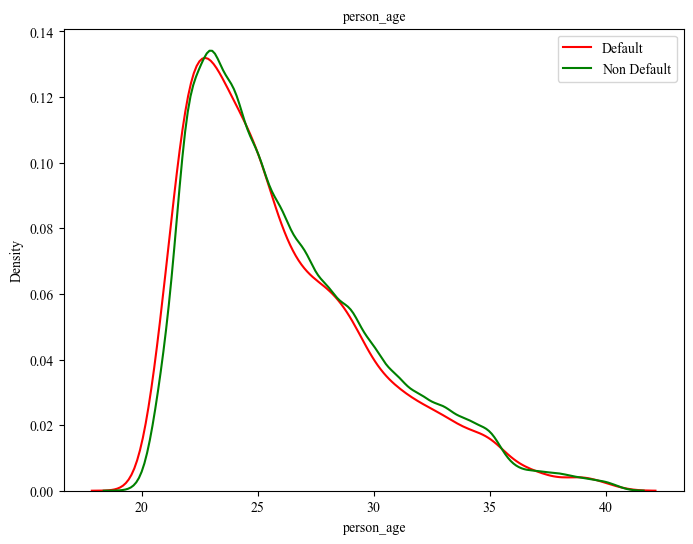

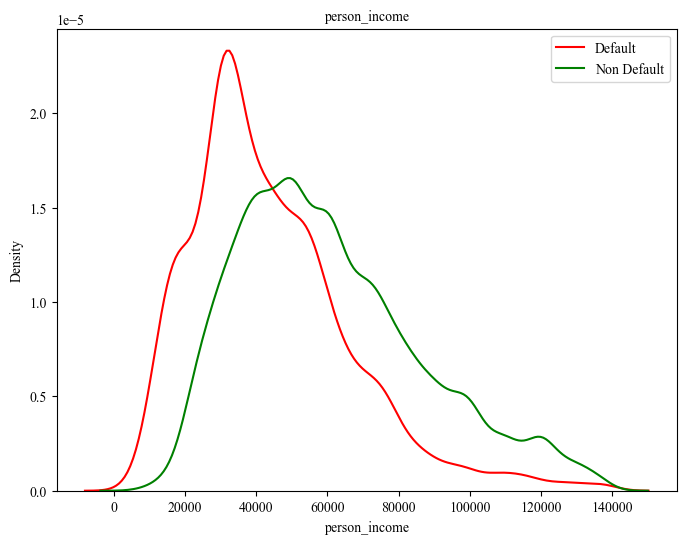

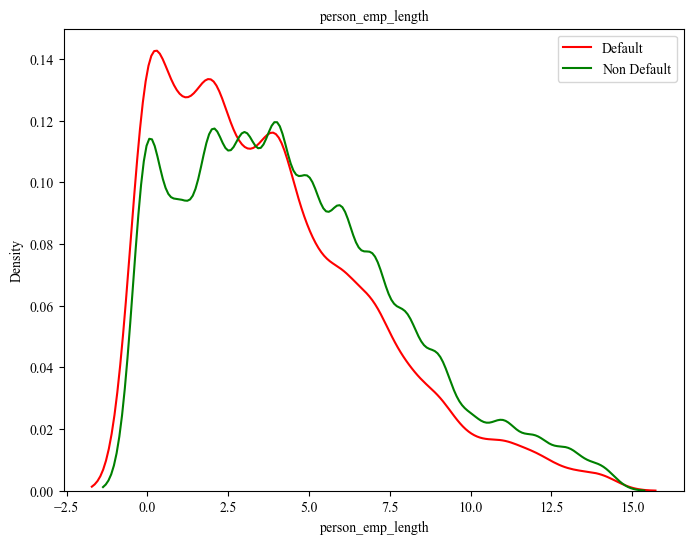

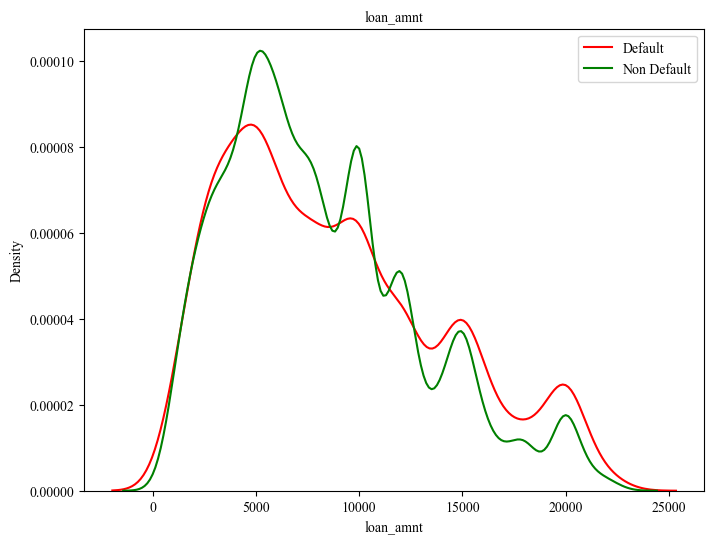

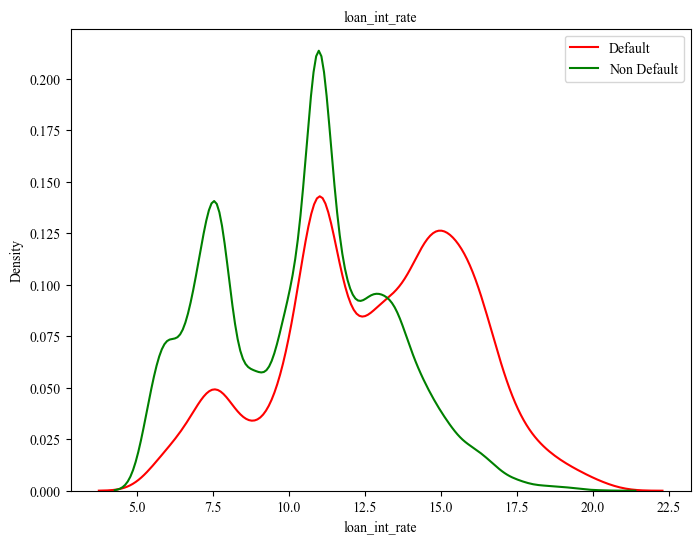

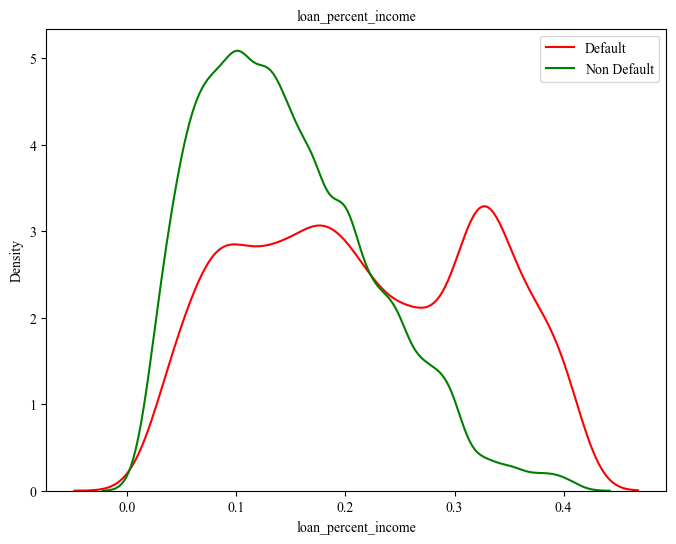

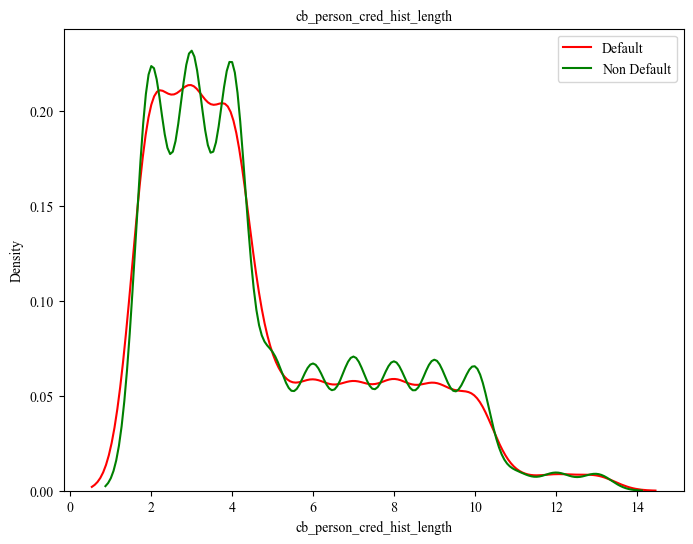

In [40]:
import matplotlib.pyplot as plt
import seaborn as sns

# Parametry do kontroli wyglądu
figsize = (8,6)       # rozmiar pojedynczego wykresu
title_size = 10        # rozmiar tytułu
label_size = 10        # rozmiar etykiet osi
legend_size = 10       # rozmiar legendy

# Pętla po zmiennych numerycznych
for cecha in Kolumny_numeryczne:
    plt.figure(figsize=figsize)
    
    # Wykres dla osób z default
    sns.kdeplot(
        data=data_proc[data_proc["loan_status"]==1],
        x=cecha,
        fill=False,
        color="red",
        label="Default"
    )
    
    # Wykres dla osób bez default
    sns.kdeplot(
        data=data_proc[data_proc["loan_status"]==0],
        x=cecha,
        fill=False,
        color="green",
        label="Non Default"
    )
    
    # Tytuły i legendy
    plt.title(cecha, fontsize=title_size)
    plt.xlabel(cecha, fontsize=label_size)
    plt.ylabel("Density", fontsize=label_size)
    plt.legend(fontsize=legend_size)
    
    plt.show()


['person_age', 'person_income', 'person_emp_length', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length'] to moje nazwy zmiennych

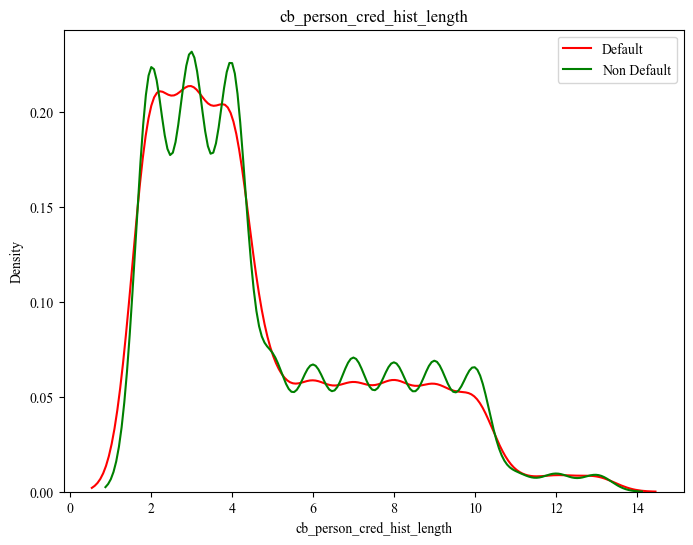

In [73]:
plt.figure(figsize=(8,6)) 
sns.kdeplot( data=data_proc[data_proc["loan_status"]==1], 
            x="cb_person_cred_hist_length", color="red", label="Default" ) 
sns.kdeplot( data=data_proc[data_proc["loan_status"]==0], 
            x="cb_person_cred_hist_length", color="green", label="Non Default" ) 
plt.title("cb_person_cred_hist_length") 
plt.xlabel("cb_person_cred_hist_length") 
plt.ylabel("Density") 
plt.legend() 
plt.show()

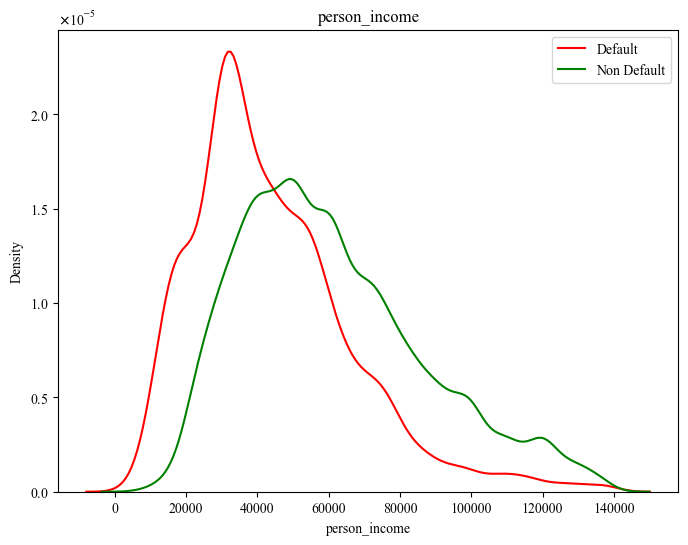

In [68]:
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as mticker

plt.figure(figsize=(8,6))

sns.kdeplot(
    data=data_proc[data_proc["loan_status"]==1],
    x="person_income",
    color="red",
    label="Default"
)

sns.kdeplot(
    data=data_proc[data_proc["loan_status"]==0],
    x="person_income",
    color="green",
    label="Non Default"
)

plt.title("person_income")
plt.xlabel("person_income")
plt.ylabel("Density")
plt.legend()

# zmiana formatu osi Y na 10^x
ax = plt.gca()
formatter = mticker.ScalarFormatter(useMathText=True)
formatter.set_powerlimits((-5, 5))
ax.yaxis.set_major_formatter(formatter)

plt.show()

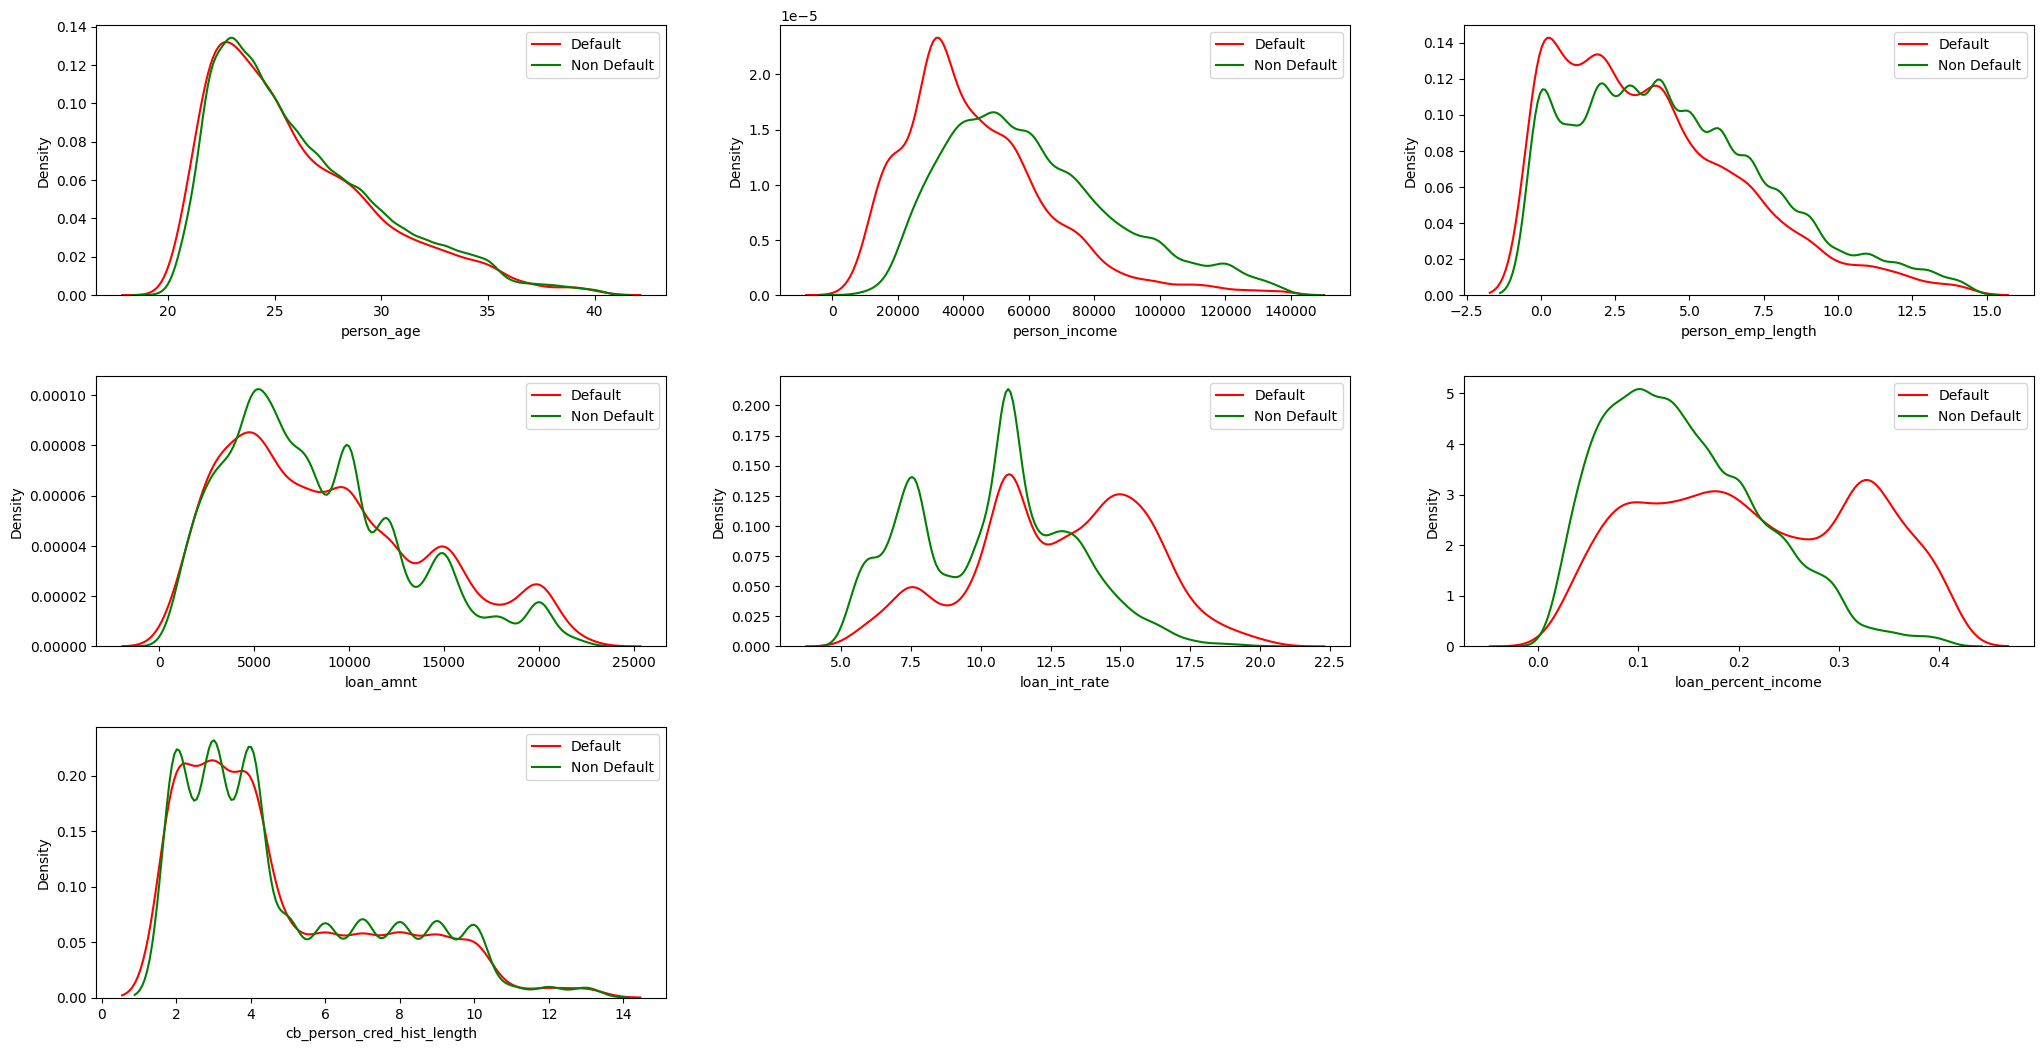

In [175]:
fig = plt.figure(figsize=(25,40))
for i , cecha in enumerate(Kolumny_numeryczne):
    ax = fig.add_subplot(9,3,i+1)
    sns.distplot(data_proc.loc[data_proc["loan_status"]==1,cecha],hist = False, ax=ax,color="red", label="Default")
    sns.distplot(data_proc.loc[data_proc["loan_status"]==0,cecha],hist = False, ax=ax, label="Non Default", color="green")
    plt.legend()
plt.subplots_adjust(hspace = 0.3, wspace = 0.2)
plt.show()

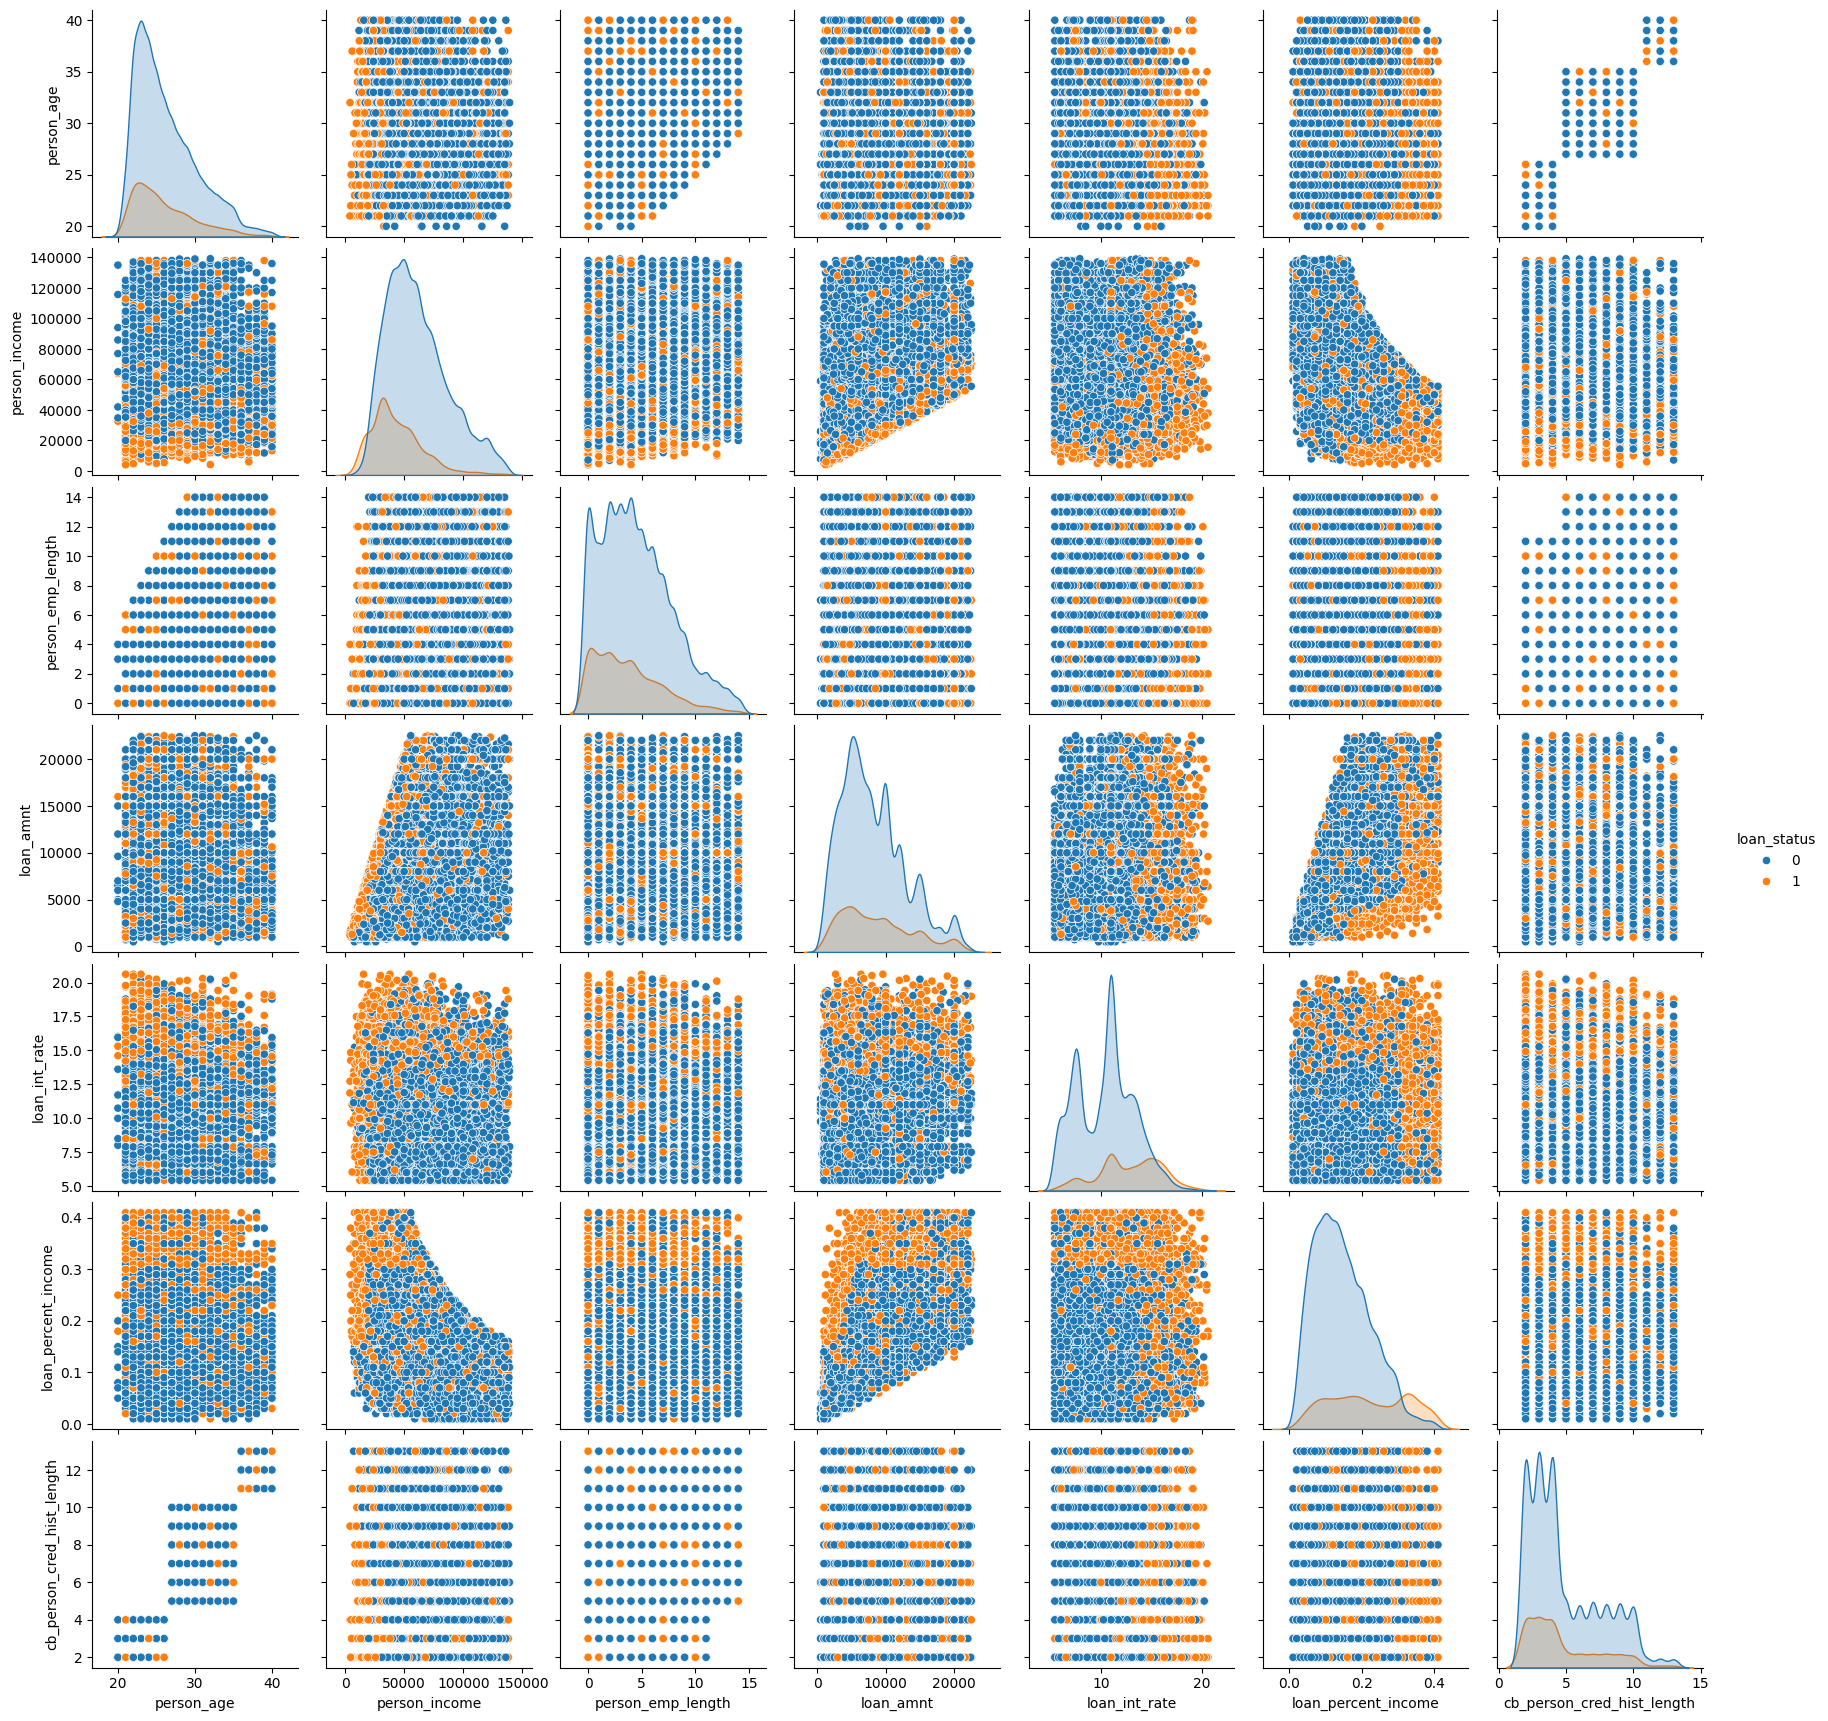

In [171]:
sns.pairplot(data_proc,hue='loan_status')

## Budowa modelu - dobór próby

In [19]:
data_proc['loan_to_income_ratio'] = data_proc['loan_amnt'] / data_proc['person_income']

data_proc['loan_to_emp_length_ratio'] =  data_proc['person_emp_length']/ data_proc['loan_amnt'] 

data_proc['int_rate_to_loan_amt_ratio'] = data_proc['loan_int_rate'] / data_proc['loan_amnt']

In [20]:
data_proc['age_group'] = pd.cut(data_proc['person_age'],
                           bins=[19, 26, 36, 46, 56, 66, 76, 86, 98, 106],
                           labels=['20-25', '26-35', '36-45', '46-55', '56-65','66-75', '76-85', '86-95', '96-105'])
data_proc['age_group'].dtype
CategoricalDtype(categories=['20-25', '26-35', '36-45', '46-55', '56-65','66-75', '76-85', '86-95', '96-105'], ordered=True)
data_proc.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,loan_to_income_ratio,loan_to_emp_length_ratio,int_rate_to_loan_amt_ratio,age_group
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2,0.104167,0.005000,0.011140,20-25
5,21,9900,OWN,2.0,VENTURE,A,2500,7.14,1,0.25,N,2,0.252525,0.000800,0.002856,20-25
9,21,10000,OWN,6.0,VENTURE,D,1600,14.74,1,0.16,N,3,0.160000,0.003750,0.009213,20-25
19,24,10800,MORTGAGE,8.0,EDUCATION,B,1750,10.99,1,0.16,N,2,0.162037,0.004571,0.006280,20-25
23,24,10980,OWN,0.0,PERSONAL,A,1500,7.29,0,0.14,N,3,0.136612,0.000000,0.004860,20-25


In [21]:
data_proc['income_group'] = pd.cut(data_proc['person_income'],
                              bins=[0, 25000, 50000, 75000, 100000, float('inf')],
                              labels=['low', 'low-middle', 'middle', 'high-middle', 'high'])
data_proc['income_group']

1           low
5           low
9           low
19          low
23          low
          ...  
32256    middle
32258    middle
32269       low
32285       low
32293      high
Name: income_group, Length: 26006, dtype: category
Categories (5, str): ['low' < 'low-middle' < 'middle' < 'high-middle' < 'high']

In [22]:
data_proc['loan_amount_group'] = pd.cut(data_proc['loan_amnt'],
                                   bins=[0, 5000, 10000, 15000, float('inf')],
                                   labels=['small', 'medium', 'large', 'very large'])
data_proc['loan_amount_group']

1             small
5             small
9             small
19            small
23            small
            ...    
32256    very large
32258         small
32269         small
32285         small
32293    very large
Name: loan_amount_group, Length: 26006, dtype: category
Categories (4, str): ['small' < 'medium' < 'large' < 'very large']

In [23]:
data_proc.reset_index(inplace = True)
data_proc = data_proc.drop(['index'], axis=1)
data_proc['person_home_ownership'].value_counts()

person_home_ownership
RENT        13697
MORTGAGE    10206
OWN          2022
OTHER          81
Name: count, dtype: int64

In [24]:
raw_data = data_proc.copy()

In [25]:
col_list = ['person_age',#
 'person_income',#
 'person_home_ownership',#
 'person_emp_length',#
 'loan_intent', #
 'loan_grade',#
 'loan_amnt',#
 'loan_int_rate',#
 'loan_status',#
 'loan_percent_income',#
 'cb_person_default_on_file',#
 'cb_person_cred_hist_length',
'age_group','income_group','loan_amount_group']

drop_colums = []
scale_cols = ['person_income','person_age','person_emp_length', 'loan_amnt','loan_int_rate','cb_person_cred_hist_length','loan_percent_income','loan_to_income_ratio', 'loan_to_emp_length_ratio',
       'int_rate_to_loan_amt_ratio']
ohe_colums = ['cb_person_default_on_file','loan_grade', 'person_home_ownership','loan_intent','income_group','age_group','loan_amount_group']
le_colums = []
data_proc = data_proc.drop(drop_colums, axis=1)
data_proc.columns

Index(['person_age', 'person_income', 'person_home_ownership',
       'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt',
       'loan_int_rate', 'loan_status', 'loan_percent_income',
       'cb_person_default_on_file', 'cb_person_cred_hist_length',
       'loan_to_income_ratio', 'loan_to_emp_length_ratio',
       'int_rate_to_loan_amt_ratio', 'age_group', 'income_group',
       'loan_amount_group'],
      dtype='str')

In [26]:
X = data_proc.drop(columns=[target])
Y = data_proc[target]

In [27]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(X,Y,test_size=0.2,random_state=2423)

In [28]:
print(x_train.shape,x_test.shape)

(20804, 17) (5202, 17)


In [29]:
x_train.reset_index(inplace = True)
x_test.reset_index(inplace = True)
x_train.columns

Index(['index', 'person_age', 'person_income', 'person_home_ownership',
       'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt',
       'loan_int_rate', 'loan_percent_income', 'cb_person_default_on_file',
       'cb_person_cred_hist_length', 'loan_to_income_ratio',
       'loan_to_emp_length_ratio', 'int_rate_to_loan_amt_ratio', 'age_group',
       'income_group', 'loan_amount_group'],
      dtype='str')

In [30]:
#Sprawdzenie ilości defaultów w próbce treningowej i testowej:
print(f"W próbie treningowej default rate wynosi: {round(y_train.mean()*100,4)}%")
print(f"W próbie testowej default rate wynosi: {round(y_test.mean()*100,4)}%")

W próbie treningowej default rate wynosi: 20.3663%
W próbie testowej default rate wynosi: 20.0884%


## Data Preprocessing

In [30]:
from sklearn.preprocessing import OneHotEncoder
ohe = OneHotEncoder()
ohe.fit(x_train[ohe_colums])

OneHotEncoder()

In [31]:
ohe.categories_

[array(['N', 'Y'], dtype=object),
 array(['A', 'B', 'C', 'D', 'E', 'F', 'G'], dtype=object),
 array(['MORTGAGE', 'OTHER', 'OWN', 'RENT'], dtype=object),
 array(['DEBTCONSOLIDATION', 'EDUCATION', 'HOMEIMPROVEMENT', 'MEDICAL',
        'PERSONAL', 'VENTURE'], dtype=object),
 array(['high', 'high-middle', 'low', 'low-middle', 'middle'], dtype=object),
 array(['20-25', '26-35', '36-45'], dtype=object),
 array(['large', 'medium', 'small', 'very large'], dtype=object)]

In [32]:
merge_ohe_col = np.concatenate((ohe.categories_[0], 
                ohe.categories_[1],
                ohe.categories_[2],
                ohe.categories_[3],
                ohe.categories_[4],
                ohe.categories_[5],
                ohe.categories_[6],))
merge_ohe_col

array(['N', 'Y', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'MORTGAGE', 'OTHER',
       'OWN', 'RENT', 'DEBTCONSOLIDATION', 'EDUCATION', 'HOMEIMPROVEMENT',
       'MEDICAL', 'PERSONAL', 'VENTURE', 'high', 'high-middle', 'low',
       'low-middle', 'middle', '20-25', '26-35', '36-45', 'large',
       'medium', 'small', 'very large'], dtype=object)

In [33]:
ohe_data = pd.DataFrame(ohe.transform(x_train[ohe_colums]).toarray(),index=x_train.index, columns=merge_ohe_col)
ohe_data2 = pd.DataFrame(ohe.transform(x_test[ohe_colums]).toarray(),index=x_test.index, columns=merge_ohe_col)
X_new = pd.concat([ohe_data, x_train], axis=1)
X_new = X_new.drop(ohe_colums, axis=1)


X_new_test = pd.concat([ohe_data2, x_test], axis=1)
X_new_test = X_new_test.drop(ohe_colums, axis=1)

In [34]:
X_new.shape

(20804, 42)

In [36]:
X_new.head()

,N,Y,A,B,C,D,E,F,G,MORTGAGE,...,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,loan_to_income_ratio,loan_to_emp_length_ratio,int_rate_to_loan_amt_ratio
0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,...,23,54996,7.0,8000,14.35,0.15,4,0.145465,0.000875,0.001794
1,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,...,28,72000,9.0,18000,11.89,0.25,10,0.250000,0.000500,0.000661
2,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,...,34,60000,7.0,10175,10.99,0.17,5,0.169583,0.000688,0.001080
3,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,26,36000,3.0,7000,14.96,0.19,4,0.194444,0.000429,0.002137
4,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,23,130000,7.0,5000,5.79,0.04,4,0.038462,0.001400,0.001158


In [ ]:
#from imblearn.over_sampling import SMOTE

#smote = SMOTE(random_state=42)
#X_new, y_train = smote.fit_resample(X_new, y_train)

In [38]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler
import pandas as pd

scale_cols = [
    'person_income','person_age','person_emp_length', 'loan_amnt',
    'loan_int_rate','cb_person_cred_hist_length','loan_percent_income',
    'loan_to_emp_length_ratio','int_rate_to_loan_amt_ratio'
]

uniform_col = []
normal_col = scale_cols
bimodal_col = []

# 🔥 upewnij się, że kolumny są float
X_new[scale_cols] = X_new[scale_cols].astype(float)
X_new_test[scale_cols] = X_new_test[scale_cols].astype(float)

# --- UNIFORM ---
scaler_uniform = MinMaxScaler()
if uniform_col:
    X_new[uniform_col] = scaler_uniform.fit_transform(X_new[uniform_col])
    X_new_test[uniform_col] = scaler_uniform.transform(X_new_test[uniform_col])

# --- NORMAL ---
scaler_normal = StandardScaler()
if normal_col:
    X_new[normal_col] = scaler_normal.fit_transform(X_new[normal_col])
    X_new_test[normal_col] = scaler_normal.transform(X_new_test[normal_col])

# --- BIMODAL ---
scaler_bimodal = RobustScaler()
if bimodal_col:
    X_new[bimodal_col] = scaler_bimodal.fit_transform(X_new[bimodal_col])
    X_new_test[bimodal_col] = scaler_bimodal.transform(X_new_test[bimodal_col])
#X_new.loc[:,bimodal_col] = scaler_bimodal.fit_transform(X_new.loc[:,bimodal_col])
#X_new_test.loc[:,bimodal_col] = scaler_bimodal.transform(X_new_test.loc[:,bimodal_col])

In [39]:
X_new_test.head()

,N,Y,A,B,C,D,E,F,G,MORTGAGE,...,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,loan_to_income_ratio,loan_to_emp_length_ratio,int_rate_to_loan_amt_ratio
0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.209985,-0.213261,-0.102476,0.338228,0.299142,0.327300,0.802280,0.192308,-0.366766,-0.432737
1,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,1.209985,-1.047604,-1.310183,-0.697996,0.530141,0.105232,0.433549,0.166667,-0.767241,0.253120
2,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,-0.043614,-0.327187,0.199451,-0.697996,-1.004352,-0.672005,-0.672646,0.102049,0.233946,-0.229001
3,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,1.460704,-0.364960,1.105232,-0.656547,-1.816149,-0.560971,0.064817,0.108333,0.773047,-0.505673
4,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,2.965023,0.279759,-0.102476,-0.801619,0.827140,-1.005107,2.645939,0.069231,0.122703,0.501151


## Machine learning - modele klasyfikacyjne

##### 1️⃣ Logistic Regression (lrc)

- Najbardziej interpretowalny
- Wymagany regulacjami w wielu bankach
- Daje wgląd w wpływ zmiennych (tzw. scorecards)
- Super punkt odniesienia

2️⃣ Gradient Boosting Models
Te modele działają najlepiej jakościowo, najbardziej typowe w produkcji dla predictive credit scoring:

➡ XGBoost (xgb)

- bardzo wysoka skuteczność
- super radzi sobie z niezbalansowanymi danymi
- często wygrywa zawody Kaggle
- mniej interpretowalny

➡ LightGBM (lgb – LGBMClassifier)

- szybszy niż XGBoost
- wysoka skuteczność
- najlepszy dla dużych datasetów
- potrafi wychwycić skomplikowane zależności

➡ CatBoost (cat)

- działa świetnie na zmiennych kategorycznych
- nie wymaga OneHotEncoding
- bardzo stabilny model
- trochę wolniejszy

✔ Top 3:
➡ XGB
➡ LGBM
➡ CatBoost

3️⃣ RandomForest (rfc)

- łatwy, stabilny
- mniej podatny na overfitting niż drzewo
- gorszy od XGB/LGBM/CatBoost
- słabo radzi sobie z nieliniowością przy dużej liczbie cech

In [40]:
svc = SVC(class_weight = 'balanced')
knc = KNeighborsClassifier() #algorithm='ball_tree', leaf_size=10, n_neighbors=18, p=1, weights='distance'
mnb = MultinomialNB()
dtc = DecisionTreeClassifier()
lrc = LogisticRegression(class_weight = 'balanced')
rfc = RandomForestClassifier()
abc = AdaBoostClassifier()
bc = BaggingClassifier()
etc = ExtraTreesClassifier()
gbdt = GradientBoostingClassifier()
xgb = XGBClassifier()
cat = CatBoostClassifier(verbose=0) 
lgb = LGBMClassifier() 

In [42]:
clf = {
     'SVC': svc,
     'KN' : knc, 
     'DT': dtc, 
     'LR': lrc, 
     'RF': rfc, 
     'AdaBoost': abc, 
     'BgC': bc, 
     'ETC': etc,
     'GBDT':gbdt,
     'xgb':xgb,
     'cat':cat,
     'lgb':LGBMClassifier(force_col_wise=True, random_state=42,verbosity=-1)
 }

In [43]:
from sklearn.metrics import precision_score, accuracy_score, recall_score, confusion_matrix

def train_classifier(clf, X_train, y_train, X_test, y_test):
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
  
    
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)

    
    # Calculate confusion matrix to get TN and FP for specificity
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    specificity = tn / (tn + fp)
   
    
    return accuracy, precision, recall, specificity

In [44]:
accuracy_scores = []
precision_scores = []
recall_scores = []
specificity_scores = []


for name,clf in clf.items():
    
    current_accuracy,current_precision, current_recall, current_specificity = train_classifier(clf, X_new,y_train,X_new_test,y_test)
    
    print("For ",name)
    print("Accuracy - ",current_accuracy)
    print("Precision - ",current_precision)
    print("Recall - ",current_recall)
    print("Specificity - ",current_specificity)
    print()
    
    accuracy_scores.append(current_accuracy)
    precision_scores.append(current_precision)
    recall_scores.append(current_recall)
    specificity_scores.append(current_specificity)
   

For  SVC
Accuracy -  0.759515570934256
Precision -  0.32241379310344825
Recall -  0.17894736842105263
Specificity -  0.9054606687515034

For  KN
Accuracy -  0.8077662437524029
Precision -  0.545271629778672
Recall -  0.25933014354066986
Specificity -  0.945633870579745

For  DT
Accuracy -  0.8923490965013456
Precision -  0.7247451343836886
Recall -  0.7483253588516746
Specificity -  0.9285542458503728

For  LR
Accuracy -  0.792964244521338
Precision -  0.4905325443786982
Recall -  0.7933014354066986
Specificity -  0.7928794803945153

For  RF
Accuracy -  0.9313725490196079
Precision -  0.9562334217506632
Recall -  0.6899521531100479
Specificity -  0.9920615828722636

For  AdaBoost
Accuracy -  0.8867743175701653
Precision -  0.7814814814814814
Recall -  0.6057416267942584
Specificity -  0.9574212172239596

For  BgC
Accuracy -  0.9332948865820838
Precision -  0.9544270833333334
Recall -  0.7014354066985646
Specificity -  0.9915804666827038

For  ETC
Accuracy -  0.9252210688196847
Precisio

## Oficjalne modele

In [75]:
models = {
     'LR': lrc, 
     'RF': rfc, 
     'GBDT':gbdt,
     'xgb':xgb,
     'cat':cat,
     'lgb':LGBMClassifier(force_col_wise=True, random_state=42,verbosity=-1)
 }

In [76]:
from sklearn.metrics import precision_score, accuracy_score, recall_score, confusion_matrix

def train_classifier(clf, X_train, y_train, X_test, y_test):
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
   
    
    # Calculate confusion matrix to get TN and FP for specificity
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    specificity = tn / (tn + fp)
    
    
    return accuracy, precision, recall, specificity

In [77]:
from sklearn.metrics import f1_score, roc_auc_score, precision_score, recall_score

results = {}

for name, clf in models.items():
    
    clf.fit(X_new, y_train)
    
    # ===== TRAIN =====
    y_train_pred = clf.predict(X_new)
    y_train_proba = clf.predict_proba(X_new)[:, 1]
    
    train_auc = roc_auc_score(y_train, y_train_proba)
    train_gini = 2 * train_auc - 1
    
    train_accuracy = (y_train_pred == y_train).mean()
    train_precision = precision_score(y_train, y_train_pred)
    train_recall = recall_score(y_train, y_train_pred)
    train_specificity = ((y_train == 0) & (y_train_pred == 0)).sum() / (y_train == 0).sum()
    train_f1 = f1_score(y_train, y_train_pred)
    
    # ===== TEST =====
    y_test_pred = clf.predict(X_new_test)
    y_test_proba = clf.predict_proba(X_new_test)[:, 1]
    
    test_auc = roc_auc_score(y_test, y_test_proba)
    test_gini = 2 * test_auc - 1
    
    test_accuracy = (y_test_pred == y_test).mean()
    test_precision = precision_score(y_test, y_test_pred)
    test_recall = recall_score(y_test, y_test_pred)
    test_specificity = ((y_test == 0) & (y_test_pred == 0)).sum() / (y_test == 0).sum()
    test_f1 = f1_score(y_test, y_test_pred)
    
    print(f"=== Model: {name} ===")
    print("TRAINING SET:")
    print(f"Accuracy: {train_accuracy:.4f}, Precision: {train_precision:.4f}, Recall: {train_recall:.4f}, Specificity: {train_specificity:.4f}, F1-score: {train_f1:.4f}, AUC: {train_auc:.4f}, Gini: {train_gini:.4f}")
    
    print("TEST SET:")
    print(f"Accuracy: {test_accuracy:.4f}, Precision: {test_precision:.4f}, Recall: {test_recall:.4f}, Specificity: {test_specificity:.4f}, F1-score: {test_f1:.4f}, AUC: {test_auc:.4f}, Gini: {test_gini:.4f}")
    print()
    
    results[name] = {
        'train_accuracy': train_accuracy,
        'train_precision': train_precision,
        'train_recall': train_recall,
        'train_specificity': train_specificity,
        'train_f1': train_f1,
        'train_auc': train_auc,
        'train_gini': train_gini,
        'test_accuracy': test_accuracy,
        'test_precision': test_precision,
        'test_recall': test_recall,
        'test_specificity': test_specificity,
        'test_f1': test_f1,
        'test_auc': test_auc,
        'test_gini': test_gini
    }

=== Model: LR ===
TRAINING SET:
Accuracy: 0.7809, Precision: 0.4770, Recall: 0.7845, Specificity: 0.7800, F1-score: 0.5933, AUC: 0.8539, Gini: 0.7078
TEST SET:
Accuracy: 0.7930, Precision: 0.4905, Recall: 0.7933, Specificity: 0.7929, F1-score: 0.6062, AUC: 0.8609, Gini: 0.7217

=== Model: RF ===
TRAINING SET:
Accuracy: 1.0000, Precision: 1.0000, Recall: 1.0000, Specificity: 1.0000, F1-score: 1.0000, AUC: 1.0000, Gini: 1.0000
TEST SET:
Accuracy: 0.9312, Precision: 0.9574, Recall: 0.6880, Specificity: 0.9923, F1-score: 0.8007, AUC: 0.9225, Gini: 0.8449

=== Model: GBDT ===
TRAINING SET:
Accuracy: 0.9248, Precision: 0.9318, Recall: 0.6807, Specificity: 0.9873, F1-score: 0.7867, AUC: 0.9253, Gini: 0.8506
TEST SET:
Accuracy: 0.9281, Precision: 0.9296, Recall: 0.6947, Specificity: 0.9868, F1-score: 0.7952, AUC: 0.9212, Gini: 0.8424

=== Model: xgb ===
TRAINING SET:
Accuracy: 0.9742, Precision: 0.9960, Recall: 0.8768, Specificity: 0.9991, F1-score: 0.9326, AUC: 0.9979, Gini: 0.9959
TEST SET:


In [47]:
accuracy_scores = []
precision_scores = []
recall_scores = []
specificity_scores = []

for name,clf in models.items():
    
    current_accuracy,current_precision, current_recall, current_specificity = train_classifier(clf, X_new,y_train,X_new_test,y_test)
    
    print("For ",name)
    print("Accuracy - ",current_accuracy)
    print("Precision - ",current_precision)
    print("Recall - ",current_recall)
    print("Specificity - ",current_specificity)
    print()
    
    accuracy_scores.append(current_accuracy)
    precision_scores.append(current_precision)
    recall_scores.append(current_recall)
    specificity_scores.append(current_specificity)

For  LR
Accuracy -  0.792964244521338
Precision -  0.4905325443786982
Recall -  0.7933014354066986
Specificity -  0.7928794803945153

For  RF
Accuracy -  0.9319492502883506
Precision -  0.9588313413014609
Recall -  0.6909090909090909
Specificity -  0.9925426990618235

For  GBDT
Accuracy -  0.9281045751633987
Precision -  0.9295774647887324
Recall -  0.6947368421052632
Specificity -  0.9867693047871061

For  xgb
Accuracy -  0.9446366782006921
Precision -  0.965559655596556
Recall -  0.7511961722488039
Specificity -  0.9932643733461631

For  cat
Accuracy -  0.9430988081507112
Precision -  0.9795134443021767
Recall -  0.7320574162679426
Specificity -  0.9961510704835218

For  lgb
Accuracy -  0.9379084967320261
Precision -  0.9762532981530343
Recall -  0.7081339712918661
Specificity -  0.995669954293962



| Model                        | Interpretacja metryk                                                                                                                                     | Co model robi dobrze                                                                     | Co model robi źle                                                                             | Wniosek                                                                                  |
| ---------------------------- | -------------------------------------------------------------------------------------------------------------------------------------------------------- | ---------------------------------------------------------------------------------------- | --------------------------------------------------------------------------------------------- | ---------------------------------------------------------------------------------------- |
| **LR (Logistic Regression)** | Accuracy 86.4% – najniższe; Precision 74% – sporo fałszywych alarmów; Recall 49.9% – **wykrywa mniej niż połowę złych klientów**; Specificity 95.6% – OK | Jest szybki i prosty; dobrze rozpoznaje dobrych klientów                                 | **Nie radzi sobie z wykrywaniem ryzyka (Recall 0.49)**; nie łapie nieliniowości; underfitting | ❌ Najsłabszy model – zupełnie niewystarczający dla ryzyka kredytowego                    |
| **RF (Random Forest)**       | Accuracy 93.3%; Precision 96.6% – bardzo mało błędnych alarmów; Recall 68.9% – średni; Specificity 99.4% – prawie nie myli dobrych klientów              | Bardzo pewne decyzje, wysoka precision; bardzo rzadko oznacza dobrego klienta jako złego | Przepuszcza 31% złych klientów; konserwatywny model                                           | 🟡 Solidny, ale mniej skuteczny niż XGB/CAT/LGB                                          |
| **GBDT**                     | Accuracy 92.8%; Precision 92.9%; Recall 69.4%; Specificity 98.7%                                                                                         | Dobry balans precision–recall; stabilny                                                  | Słabszy niż nowoczesne boostery; przepuszcza ok. 30% ryzyka                                   | 🟡 Poprawny, ale wyraźnie słabszy od XGB i CAT                                           |
| **XGBoost**                  | Accuracy 94.2%; Precision 95.5%; Recall **74.5% – najlepszy w wykrywaniu złych klientów**; Specificity 99.1%                                             | **Najwyższy recall**; bardzo dobra precision; świetna równowaga metryk                   | Minimalnie mniej precyzyjny niż CatBoost                                                      | 🟢 **Najlepszy model ogólnie – najwyższa skuteczność wykrywania ryzyka**                 |
| **CatBoost**                 | Accuracy 94.3%; Precision **97.8% – najwyższa ze wszystkich**; Recall 73.2%; Specificity **99.6% – prawie zero błędów na dobrych klientach**             | **Najbardziej precyzyjny model**; minimalne fałszywe alarmy; bardzo stabilny             | Złapiesz trochę mniej złych klientów niż XGB                                                  | 🟢 **Najbezpieczniejszy biznesowo – najlepiej chroni przed odrzuceniem dobrego klienta** |
| **LightGBM**                 | Accuracy 93.8%; Precision 97.6%; Recall 70.8%; Specificity 99.6%                                                                                         | Bardzo wysoka precision; świetna specificity; szybki i stabilny                          | Recall niższy niż XGB i CatBoost                                                              | 🟢 Bardzo mocny model, lekko słabszy niż XGB/Cat                                         |


## Tunning hyperparametrów

In [132]:
print(X_new.columns.difference(X_new.columns))
print(X_new_test.columns.difference(X_new.columns))

Index([], dtype='object')
Index([], dtype='object')


#### RandomizedSearchCV

In [48]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

param_distributions_lr = {
    'C': [0.01, 0.1, 1, 10, 100],
    'penalty': ['l2'], 
    'solver': ['lbfgs'],
    'max_iter': [100, 500, 1000]
}

param_distributions_rf = {
    'n_estimators': [100,200,400,800],
    'max_depth': [None,5,10,20],
    'min_samples_split': [2,5,10],
    'min_samples_leaf': [1,2,4]
}

param_distributions_gbdt = {
    'n_estimators': [100, 200, 400],
    'learning_rate': [0.01, 0.05, 0.1],
    'max_depth': [3, 5, 8],
    'subsample': [0.6, 0.8, 1.0]
}

param_distributions_xgb = {
    'n_estimators': [100,200,400],
    'max_depth': [3,5,8],
    'learning_rate': [0.01,0.05,0.1],
    'subsample': [0.6,0.8,1.0],            
    'colsample_bytree': [0.6, 0.4],     
    'gamma': [0, 5],                    
    'reg_alpha': [0, 5],                 
    'reg_lambda': [0, 5]  
}

#param_distributions_cat = {
#    'iterations': [100, 200, 400],
#    'learning_rate': [0.01, 0.05, 0.1],
#    'depth': [3, 5, 8],
#    'l2_leaf_reg': [1, 3, 5, 7]
#}

tune_models = ['LR','RF','GBDT','xgb']
best_estimators = {}
searches = {}

for name in tune_models:
    if name not in models:
        continue
    print("Tuning:", name)
    clf = models[name]
    if name == 'LR':
        param_dist = param_distributions_lr
    elif name == 'RF':
        param_dist = param_distributions_rf
    elif name == 'GBDT':
        param_dist = param_distributions_gbdt
    elif name == 'xgb':
        param_dist = param_distributions_xgb
    #elif name == 'cat':
    #    param_dist = param_distributions_cat
    else:
        param_dist = {}

    rs = RandomizedSearchCV(
        clf,
        param_distributions=param_dist,
        n_iter=30,
        scoring='roc_auc',
        cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42),
        n_jobs=-1,
        random_state=42,
        verbose=2
    )
    rs.fit(X_new, y_train)
    print("Best score:", rs.best_score_)
    print("Best params:", rs.best_params_)
    
    searches[name] = rs
    best_estimators[name] = rs.best_estimator_


Tuning: LR
Fitting 3 folds for each of 15 candidates, totalling 45 fits
Best score: 0.8706339302962696
Best params: {'solver': 'lbfgs', 'penalty': 'l2', 'max_iter': 1000, 'C': 1}
Tuning: RF
Fitting 3 folds for each of 30 candidates, totalling 90 fits
Best score: 0.9208460621860132
Best params: {'n_estimators': 400, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_depth': 20}
Tuning: GBDT
Fitting 3 folds for each of 30 candidates, totalling 90 fits
Best score: 0.9496454627806222
Best params: {'subsample': 0.8, 'n_estimators': 400, 'max_depth': 5, 'learning_rate': 0.1}
Tuning: xgb
Fitting 3 folds for each of 30 candidates, totalling 90 fits
Best score: 0.9464942950425819
Best params: {'subsample': 0.8, 'reg_lambda': 5, 'reg_alpha': 0, 'n_estimators': 400, 'max_depth': 8, 'learning_rate': 0.1, 'gamma': 0, 'colsample_bytree': 0.4}


## Bayesian Optimization

## UWAGA TRWA 3H

In [ ]:
import numpy as np
from sklearn.model_selection import cross_val_score, StratifiedKFold
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from bayes_opt import BayesianOptimization

#Stratified CV
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=12)

#LightGBM
def lgbm_clf_bo(num_leaves, max_depth, learning_rate, min_child_weight, subsample, colsample_bytree):
    params_lgbm = {'objective': 'binary'}
    params_lgbm['num_leaves'] = round((2**round(max_depth)) * num_leaves)
    params_lgbm['max_depth'] = round(max_depth)
    params_lgbm['learning_rate'] = learning_rate
    params_lgbm['min_child_weight'] = min_child_weight
    params_lgbm['subsample'] = subsample
    params_lgbm['colsample_bytree'] = colsample_bytree
    
    scores = cross_val_score(
        LGBMClassifier(random_state=12, **params_lgbm),
        X_new, y_train,
        scoring='recall',
        cv=cv
    ).mean()
    
    #zabezpieczenie
    if np.isnan(scores) or np.isinf(scores):
        return 0
    
    return scores

#CatBoost
def cat_clf_bo(depth, learning_rate, l2_leaf_reg, border_count, bagging_temperature):
    params_cb = {}
    params_cb['iterations'] = 1000
    params_cb['depth'] = round(depth)
    params_cb['learning_rate'] = learning_rate
    params_cb['l2_leaf_reg'] = l2_leaf_reg
    params_cb['border_count'] = round(border_count)
    params_cb['bagging_temperature'] = bagging_temperature
    params_cb['random_seed'] = 12
    params_cb['verbose'] = 0
    params_cb['loss_function'] = 'Logloss'
    
    scores = cross_val_score(
        CatBoostClassifier(**params_cb),
        X_new, y_train,
        scoring='recall',
        cv=cv
    ).mean()
    
    #zabezpieczenie
    if np.isnan(scores) or np.isinf(scores):
        return 0
    
    return scores

#zakresy parametrów
params_lgbm = {
    'num_leaves': (0.5, 0.9),
    'max_depth': (3, 15),
    'learning_rate': (0.005, 0.3),
    'min_child_weight': (1e-6, 1e-1),
    'subsample': (0.5, 1),
    'colsample_bytree': (0.5, 1)
}

params_cb = {
    'depth': (6, 10),
    'learning_rate': (0.03, 0.15),
    'l2_leaf_reg': (3, 8),
    'border_count': (64, 255),
    'bagging_temperature': (0.0, 1.0)
}

#Bayesian Optimization
lgbm_bo = BayesianOptimization(lgbm_clf_bo, params_lgbm)
lgbm_bo.maximize(init_points=2, n_iter=20)

cat_bo = BayesianOptimization(cat_clf_bo, params_cb)
cat_bo.maximize(init_points=2, n_iter=20)

|   iter    |  target   | num_le... | max_depth | learni... | min_ch... | subsample | colsam... |
-------------------------------------------------------------------------------------------------
| 1         | 0.6877509 | 0.7628731 | 5.0250503 | 0.1093126 | 0.0373476 | 0.9443219 | 0.5185078 |
| 2         | 0.7415635 | 0.5079166 | 10.579163 | 0.1772660 | 0.0561840 | 0.6574618 | 0.9478552 |
| 3         | 0.7281100 | 0.7273730 | 8.3542505 | 0.1332115 | 0.0353659 | 0.9896714 | 0.8099712 |
| 4         | 0.1276874 | 0.9       | 14.338178 | 0.005     | 1e-06     | 1.0       | 0.5       |
| 5         | 0.6787780 | 0.5       | 3.0       | 0.3       | 0.1       | 0.5       | 1.0       |
| 6         | 0.7526573 | 0.5       | 6.6832636 | 0.3       | 0.1       | 0.5       | 1.0       |
| 7         | 0.7314175 | 0.9       | 9.5427917 | 0.3       | 0.1       | 0.5       | 0.5       |
| 8         | 0.5513309 | 0.5       | 9.2786150 | 0.005     | 1e-06     | 0.5       | 1.0       |
| 9         | 0.7356

In [51]:
params_lgbm = lgbm_bo.max['params']
params_lgbm['max_depth'] = round(params_lgbm['max_depth'])
params_lgbm['num_leaves'] = round((2**round(params_lgbm['max_depth']))*params_lgbm['num_leaves'])
params_lgbm

{'num_leaves': 110,
 'max_depth': 7,
 'learning_rate': 0.3,
 'min_child_weight': 0.1,
 'subsample': 0.5,
 'colsample_bytree': 1.0}

In [52]:
params_cat = cat_bo.max['params']
params_cat['depth'] = round(params_cat['depth'])
params_cat['border_count'] = round(params_cat['border_count'])
params_cat

{'depth': 6,
 'learning_rate': 0.15,
 'l2_leaf_reg': 3.0,
 'border_count': 182,
 'bagging_temperature': 1.0}

In [53]:
best_lgbm_model = LGBMClassifier(
    objective='binary',
    random_state=42,
    **params_lgbm
)

best_lgbm_model.fit(X_new, y_train)

# DODAJEMY DO best_estimators
best_estimators['lgb'] = best_lgbm_model

In [54]:
best_cat_model = CatBoostClassifier(
    verbose=0,
    random_state=42,
    **params_cat
)

best_cat_model.fit(X_new, y_train)

# DODAJEMY DO best_estimators
best_estimators['cat'] = best_cat_model

## ROC i Confusion Matrix

In [54]:
#Funkcje ewaluacji i wykresy
def evaluate_preds(y_true, y_pred, y_proba=None):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    res = {
        'accuracy': accuracy_score(y_true, y_pred),
        'precision': precision_score(y_true, y_pred, zero_division=0),
        'recall': recall_score(y_true, y_pred, zero_division=0),
        'specificity': tn / (tn + fp) if (tn + fp) > 0 else np.nan,
        'f1': f1_score(y_true, y_pred, zero_division=0)
    }

    if y_proba is not None:
        try:
            y_proba = np.array(y_proba)

            # Jeśli masz 2 kolumny → wybierz drugą (klasa pozytywna)
            if y_proba.ndim == 2 and y_proba.shape[1] == 2:
                y_score = y_proba[:, 1]
            else:
                # jeśli masz już jednowymiarowy score/probability → użyj bez zmian
                y_score = y_proba

            auc = roc_auc_score(y_true, y_score)
            res['roc_auc'] = auc
            res['gini'] = 2 * auc - 1

        except Exception:
            res['roc_auc'] = np.nan
            res['gini'] = np.nan

    return res

In [57]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

def plot_conf_matrix(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title('Confusion matrix')
    plt.show()

In [ ]:
from sklearn.metrics import roc_curve, precision_recall_curve
import matplotlib.pyplot as plt
import numpy as np

def plot_roc_pr(y_true, y_proba, label=None):
    y_proba = np.array(y_proba)

    # jeśli macierz → wybieramy klasę pozytywną
    if y_proba.ndim == 2 and y_proba.shape[1] == 2:
        y_proba = y_proba[:, 1]

    # sprawdzenie czy dane mają sens
    if len(np.unique(y_proba)) < 2:
        print(f"⚠️ Nie można narysować ROC/PR dla {label}")
        return

    fpr, tpr, _ = roc_curve(y_true, y_proba)
    prec, rec, _ = precision_recall_curve(y_true, y_proba)

    plt.figure(figsize=(12,5))

    plt.subplot(1,2,1)
    plt.plot(fpr, tpr, label=label or 'model')
    plt.plot([0,1],[0,1],'k--', alpha=0.5)
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('ROC curve')
    plt.legend()

    plt.subplot(1,2,2)
    plt.plot(rec, prec, label=label or 'model')
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('Precision-Recall')
    plt.legend()

    plt.tight_layout()
    plt.show()

Oceniam: LR
accuracy       0.819493
precision       0.53496
recall         0.776077
specificity    0.830407
f1             0.633346
roc_auc        0.874797
gini           0.749594
model                LR
dtype: object


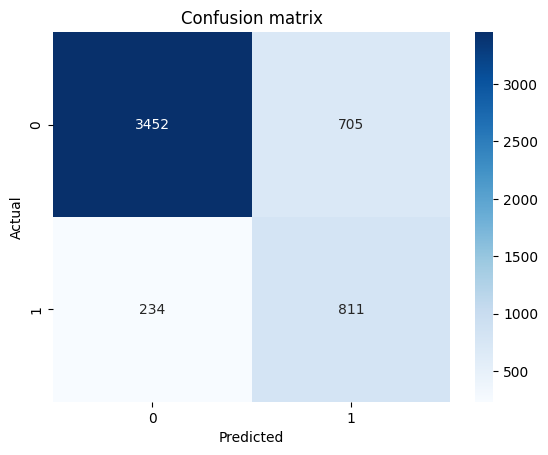

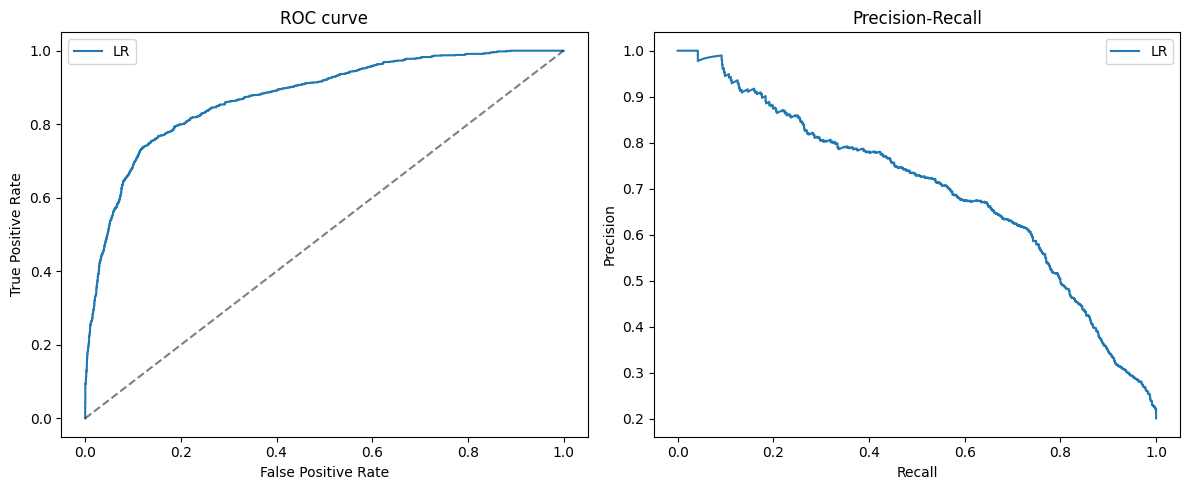

Oceniam: RF
accuracy       0.931949
precision      0.962517
recall         0.688038
specificity    0.993264
f1             0.802455
roc_auc        0.923675
gini           0.847349
model                RF
dtype: object


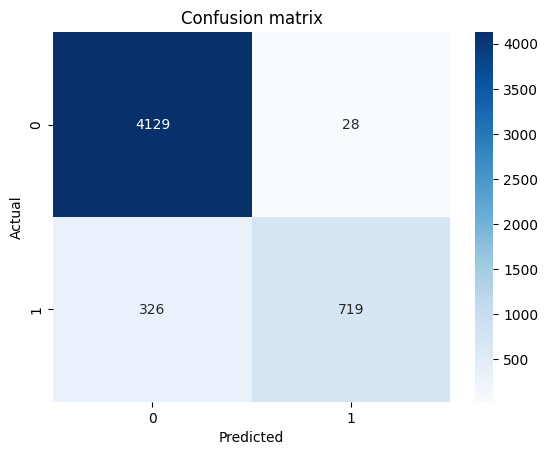

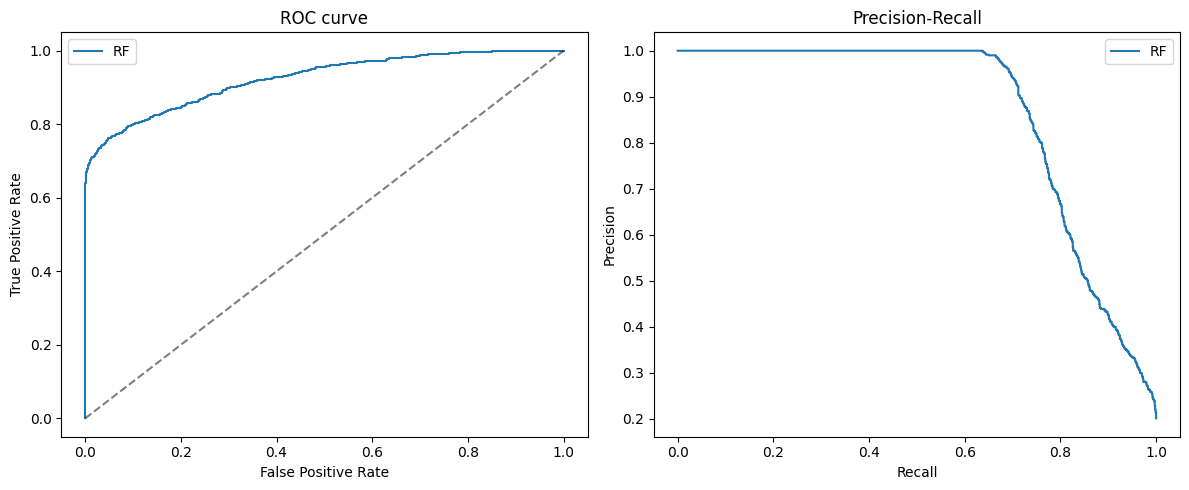

Oceniam: GBDT
accuracy       0.940408
precision      0.956522
recall         0.736842
specificity     0.99158
f1             0.832432
roc_auc        0.955375
gini           0.910749
model              GBDT
dtype: object


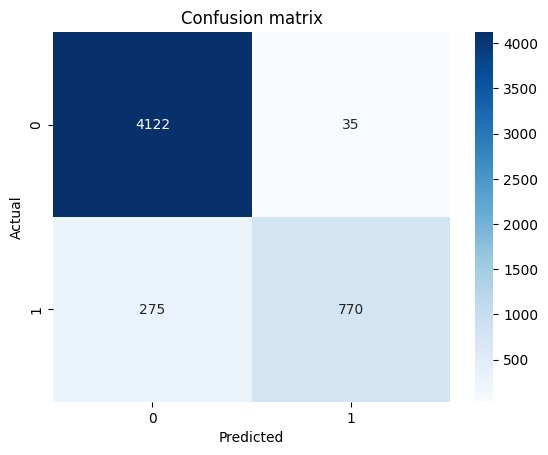

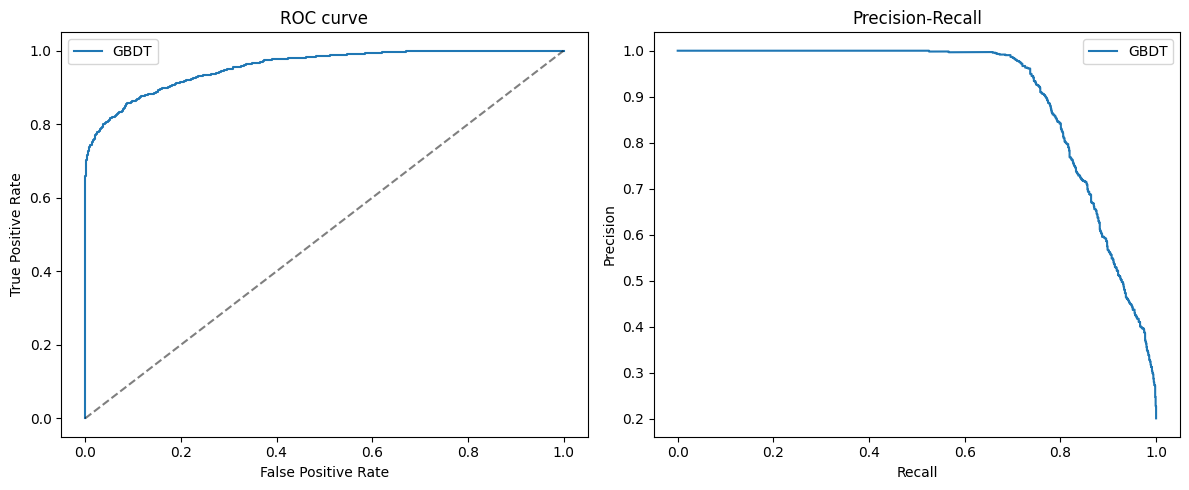

Oceniam: xgb
accuracy       0.939446
precision      0.967949
recall         0.722488
specificity    0.993986
f1             0.827397
roc_auc        0.952874
gini           0.905748
model               xgb
dtype: object


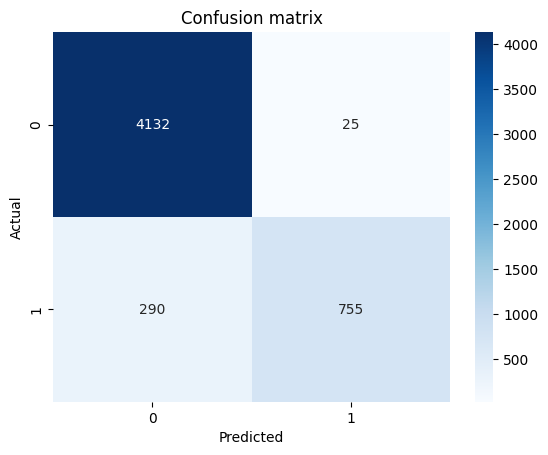

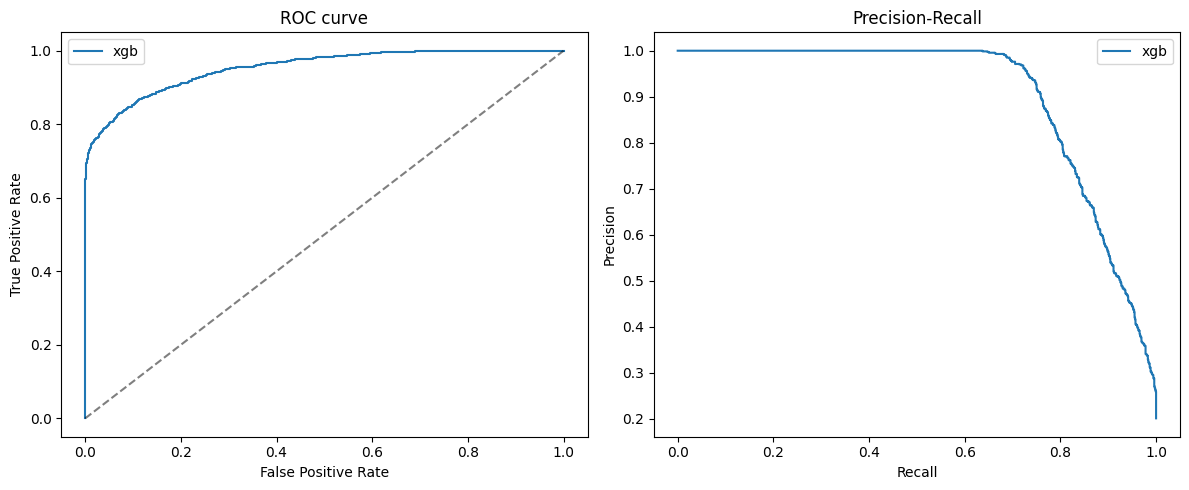

Oceniam: lgb
accuracy       0.941753
precision      0.944844
recall         0.754067
specificity    0.988934
f1             0.838744
roc_auc        0.960534
gini           0.921068
model               lgb
dtype: object


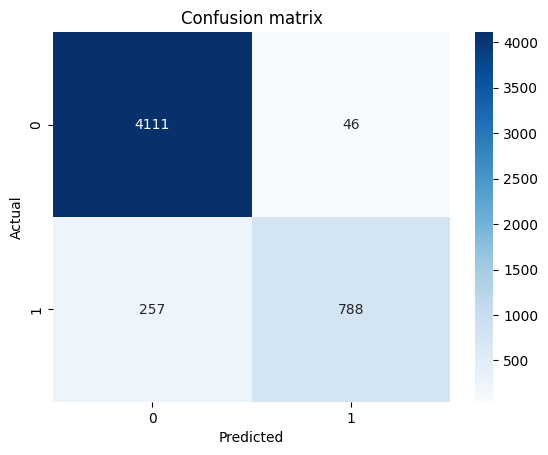

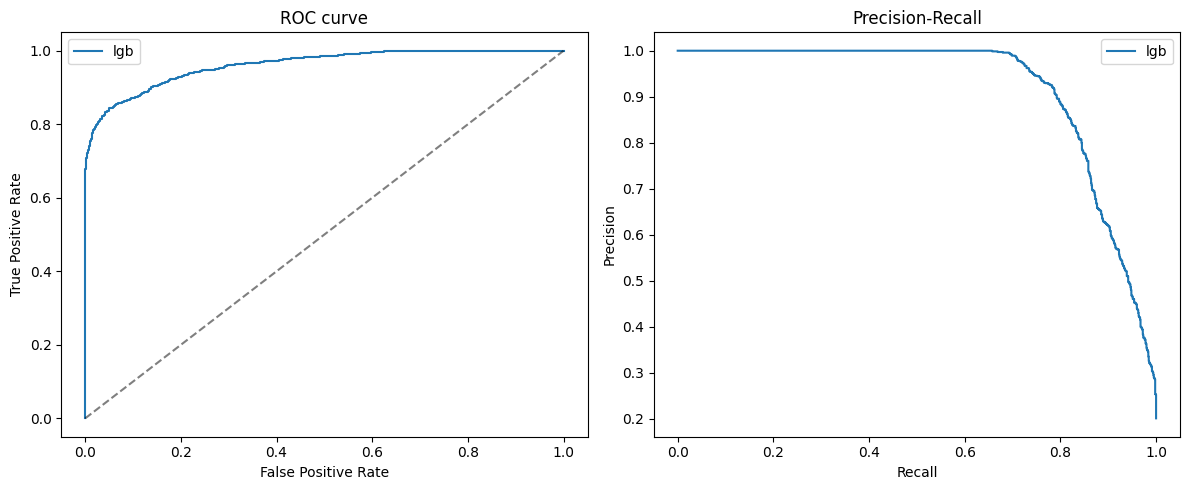

Oceniam: cat
accuracy       0.946559
precision      0.967113
recall         0.759809
specificity    0.993505
f1             0.851018
roc_auc        0.959929
gini           0.919858
model               cat
dtype: object


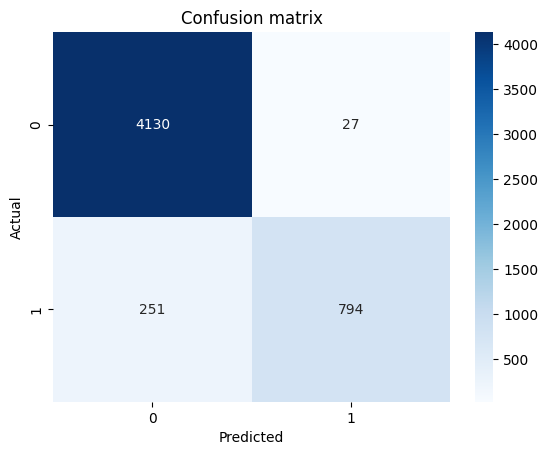

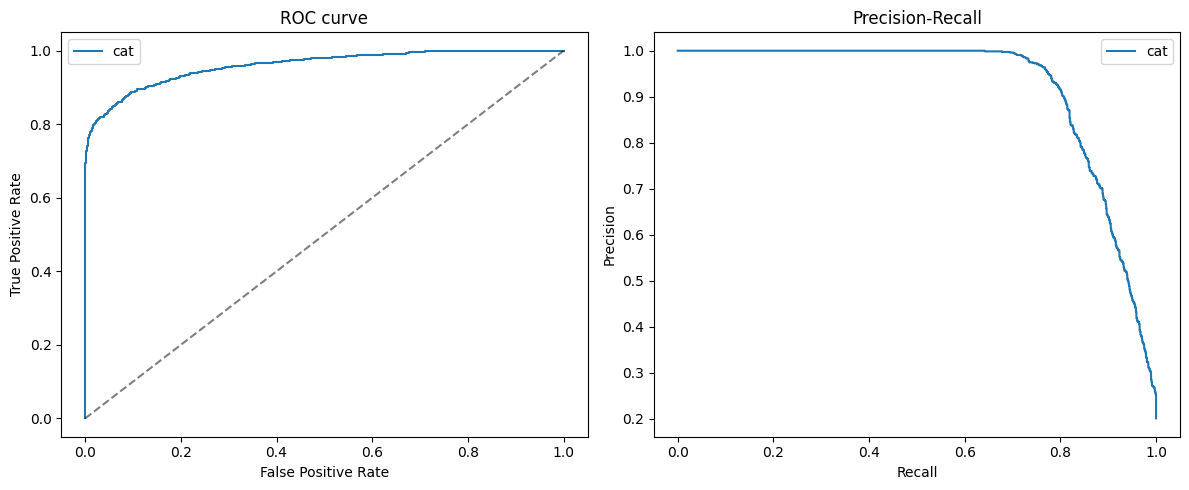

,accuracy,precision,recall,specificity,f1,roc_auc,gini
model,,,,,,,
LR,0.819493,0.534960,0.776077,0.830407,0.633346,0.874797,0.749594
RF,0.931949,0.962517,0.688038,0.993264,0.802455,0.923675,0.847349
GBDT,0.940408,0.956522,0.736842,0.991580,0.832432,0.955375,0.910749
xgb,0.939446,0.967949,0.722488,0.993986,0.827397,0.952874,0.905748
lgb,0.941753,0.944844,0.754067,0.988934,0.838744,0.960534,0.921068
cat,0.946559,0.967113,0.759809,0.993505,0.851018,0.959929,0.919858


In [ ]:
# Trening finalny i ewaluacja na zbiorze holdout
final_models = {}

for name, est in best_estimators.items():
    final_models[name] = est


# Ocena na holdout
summary = []

for name, model in final_models.items():
    print("Oceniam:", name)
    
    y_pred = model.predict(X_new_test)
    
    #Uproszczone i kompatybilne z evaluate_preds
    y_proba = None
    
    if hasattr(model, "predict_proba"):
        try:
            y_proba = model.predict_proba(X_new_test)
        except:
            y_proba = None
            
    elif hasattr(model, "decision_function"):
        try:
            df = model.decision_function(X_new_test)
            # normalizacja do [0,1]
            y_proba = (df - df.min()) / (df.max() - df.min())
        except:
            y_proba = None

    # ewaluacja (tu liczy się też Gini)
    res = evaluate_preds(y_test, y_pred, y_proba)
    res['model'] = name
    summary.append(res)

    print(pd.Series(res))
    
    plot_conf_matrix(y_test, y_pred)
    
    if y_proba is not None:
        # jeśli 2D → evaluate_preds sobie poradzi, ale tu trzeba 1D
        if isinstance(y_proba, np.ndarray) and y_proba.ndim == 2:
            y_plot = y_proba[:, 1]
        else:
            y_plot = y_proba
            
        plot_roc_pr(y_test, y_plot, label=name)

summary_df = pd.DataFrame(summary).set_index('model')
display(summary_df)


##### Dla cat

Model bardzo dobrze rozpoznaje klasę 0 (bardzo mało FP: tylko 31).

Model ma umiarkowany problem z wykrywaniem klasy 1 (FN = 248, czyli część pozytywnych przykładów nie została wykryta).

Wysoki precision i wysoki AUC mówią, że model jest pewny, gdy przewiduje klasę 1, ale recall może wymagać poprawy, jeśli wykrywanie wszystkich pozytywnych przypadków jest krytyczne.

W zależności od aplikacji można poprawić recall, np. poprzez balansowanie progu klasyfikacji.

##### Wykres ROC (po lewej)

Oś X: FPR (False Positive Rate) – odsetek fałszywych alarmów.

Oś Y: TPR (True Positive Rate, inaczej recall) – odsetek poprawnie wykrytych pozytywnych przypadków.

Linia przerywana: linia losowego klasyfikatora (y = x).

##### Interpretacja:

Krzywa ROC jest mocno wypukła ku górze, co oznacza dobrą jakość klasyfikatora.

Wysoka wartość TPR przy niskim FPR wskazuje, że model dobrze rozróżnia klasy.

Obszar pod krzywą (AUC) prawdopodobnie jest bliski 0.95, co świadczy o bardzo wysokiej skuteczności.

##### Wykres Precision-Recall (po prawej)

Oś X: Recall (czułość).

Oś Y: Precision (precyzja).

##### Interpretacja:

Precision utrzymuje się bardzo blisko 1 przy Recall do około 0.8–0.85.

Po tym punkcie precyzja gwałtownie spada, co oznacza, że model zaczyna więcej fałszywych alarmów, próbując złapać wszystkie pozytywne przypadki.

Wysoka wartość początkowa wskazuje bardzo dobre klasyfikowanie większości pozytywnych przypadków przy minimalnej liczbie fałszywych trafień.

##### Podsumowanie

Model jest bardzo skuteczny, zarówno pod względem ROC-AUC, jak i precision-recall.

Ma jednak spadek precyzji przy bardzo wysokim recall – klasyczny kompromis: łapiąc wszystkie pozytywne przypadki, zwiększa liczbę fałszywych alarmów.

## Trenowanie modelu ensemble

In [61]:
from sklearn.ensemble import VotingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

lrc = LogisticRegression()
rfc = RandomForestClassifier()
xgb_model = XGBClassifier(use_label_encoder=False, eval_metric='logloss')
cat_model = CatBoostClassifier(verbose=0) 
lgb_model = LGBMClassifier()

ensemble = VotingClassifier(
    estimators=[
        ('lrc', lrc),
        ('cat', cat_model),
        ('lgb', lgb_model),
        ('rfc', rfc),
        ('xgb', xgb_model)
    ],
    voting='soft'
)

ensemble.fit(X_new, y_train)

y_pred = ensemble.predict(X_new_test)
y_pred_proba = ensemble.predict_proba(X_new_test)[:, 1]

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_pred_proba)

tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
specificity = tn / (tn + fp)

print("For ensemble:")
print("Accuracy -", accuracy)
print("Precision -", precision)
print("Recall -", recall)
print("F1-score -", f1)
print("ROC AUC -", roc_auc)
print("Specificity -", specificity)


For ensemble:
Accuracy - 0.9382929642445214
Precision - 0.9775725593667546
Recall - 0.7090909090909091
F1-score - 0.8219633943427621
ROC AUC - 0.9525053147225008
Specificity - 0.9959105123887418


In [62]:
from sklearn.ensemble import RandomForestRegressor
regressor = RandomForestRegressor()
from sklearn.feature_selection import RFE

clf = RandomForestRegressor()


clf.fit(X_new,y_train)

feature_scores = pd.Series(clf.feature_importances_, index=X_new.columns).sort_values(ascending=False)
feature_scores

loan_to_income_ratio          0.202591
person_income                 0.119764
RENT                          0.105499
D                             0.091352
loan_int_rate                 0.086796
index                         0.056284
person_emp_length             0.038117
loan_to_emp_length_ratio      0.033163
int_rate_to_loan_amt_ratio    0.032881
person_age                    0.032141
MEDICAL                       0.031488
DEBTCONSOLIDATION             0.029800
loan_percent_income           0.018830
cb_person_cred_hist_length    0.016090
loan_amnt                     0.014991
E                             0.013288
HOMEIMPROVEMENT               0.012673
OWN                           0.011519
C                             0.009921
MORTGAGE                      0.006144
PERSONAL                      0.004765
EDUCATION                     0.004164
VENTURE                       0.004129
F                             0.003627
Y                             0.002405
N                        

In [1]:
%pip install numpy==1.26.4
%pip install shap==0.44.1

  Using cached numpy-1.26.4-cp311-cp311-win_amd64.whl.metadata (61 kB)
Using cached numpy-1.26.4-cp311-cp311-win_amd64.whl (15.8 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 2.1.3
    Uninstalling numpy-2.1.3:
      Successfully uninstalled numpy-2.1.3
Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
autogluon-common 1.4.0 requires pandas<2.4.0,>=2.0.0, but you have pandas 3.0.2 which is incompatible.
autogluon-core 1.4.0 requires pandas<2.4.0,>=2.0.0, but you have pandas 3.0.2 which is incompatible.
autogluon-core 1.4.0 requires scipy<1.17,>=1.5.4, but you have scipy 1.17.1 which is incompatible.
autogluon-features 1.4.0 requires pandas<2.4.0,>=2.0.0, but you have pandas 3.0.2 which is incompatible.
autogluon-multimodal 1.4.0 requires pandas<2.4.0,>=2.0.0, but you have pandas 3.0.2 which is incompatible.
autogluon-multimodal 1.4.0 requires scipy<1.17,>=1.5.4, but you have scipy 1.17.1 which is incompatible.
autogluon-tabular 1.4.0 requires pandas<2.4.0,>=2.0.0, but you have pandas 3.0.2 which is

  Using cached shap-0.44.1-cp311-cp311-win_amd64.whl.metadata (25 kB)
  Using cached slicer-0.0.7-py3-none-any.whl.metadata (3.7 kB)
Using cached shap-0.44.1-cp311-cp311-win_amd64.whl (450 kB)
Using cached slicer-0.0.7-py3-none-any.whl (14 kB)
  Attempting uninstall: slicer
    Found existing installation: slicer 0.0.8
    Uninstalling slicer-0.0.8:
      Successfully uninstalled slicer-0.0.8
  Attempting uninstall: shap
    Found existing installation: shap 0.50.0
    Uninstalling shap-0.50.0:
      Successfully uninstalled shap-0.50.0
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


(20804, 42)
(20804, 41)


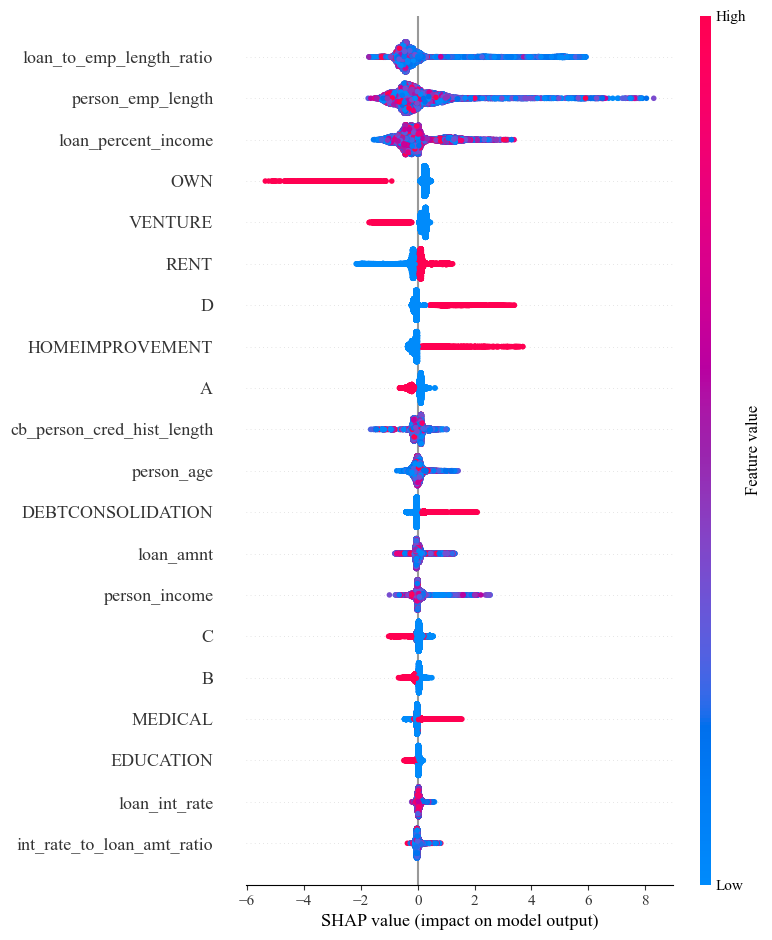

In [63]:
import shap
import matplotlib.pyplot as plt

# ustawienia czcionki
plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['font.size'] = 10

explainer = shap.TreeExplainer(clf)
shap_values = explainer.shap_values(X_new)

# shap_values jest listą, np. [array_klasa_0, array_klasa_1]
shap_class_1 = shap_values[1]

print(shap_class_1.shape)
print(X_new_no_index.shape)

# jeśli jest dodatkowa kolumna (offset), usuń
if shap_class_1.shape[1] == X_new_no_index.shape[1] + 1:
    shap_class_1 = shap_class_1[:, :-1]

# wykres
shap.summary_plot(shap_class_1, X_new_no_index)

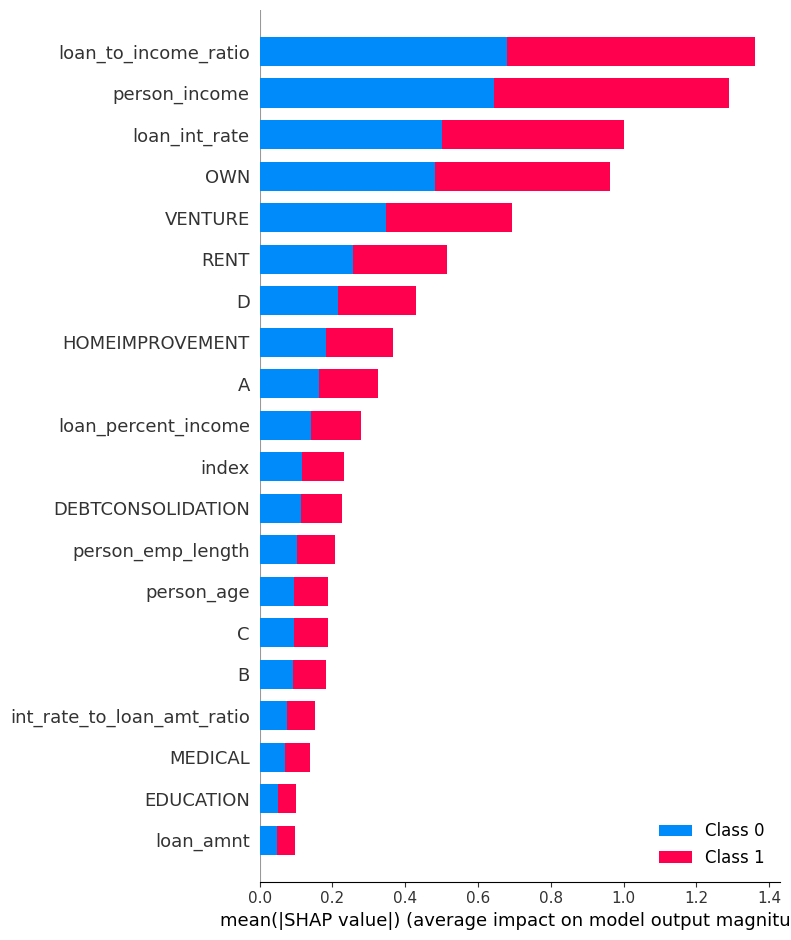

In [57]:
shap.summary_plot(shap_values, X_new, plot_type="bar")

In [126]:
# Dodanie numeracji
feature_ranking = feature_scores.reset_index()
feature_ranking.columns = ["Feature", "Importance"]
feature_ranking["Rank"] = feature_ranking.index + 1

# Wyświetlenie rankingu
feature_ranking

,Feature,Importance,Rank
0,loan_to_income_ratio,0.203687,1
1,person_income,0.119931,2
2,RENT,0.104146,3
3,D,0.091264,4
4,loan_int_rate,0.089676,5
5,index,0.055878,6
6,person_emp_length,0.038383,7
7,int_rate_to_loan_amt_ratio,0.033706,8
8,loan_to_emp_length_ratio,0.033549,9
9,MEDICAL,0.031382,10


## Auto ML używając PyCaret

In [ ]:
#Python 3.11 !!!!!
#py -3.11 -m venv pycaret_env
#pycaret_env\Scripts\activate
#pip install --upgrade pip
#pip install pycaret==3.3.2
%pip install pycaret
%pip install git+https://github.com/pycaret/pycaret.git

  Using cached scipy-1.11.4-cp311-cp311-win_amd64.whl.metadata (60 kB)
Using cached scipy-1.11.4-cp311-cp311-win_amd64.whl (44.1 MB)
  Attempting uninstall: scipy
    Found existing installation: scipy 1.9.3
    Uninstalling scipy-1.9.3:
      Successfully uninstalled scipy-1.9.3
Note: you may need to restart the kernel to use updated packages.


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
shap 0.50.0 requires numpy>=2, but you have numpy 1.25.2 which is incompatible.

[notice] A new release of pip is available: 24.0 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


  Cloning https://github.com/pycaret/pycaret.git to c:\users\klaud\appdata\local\temp\pip-req-build-qbwq4chw
  Resolved https://github.com/pycaret/pycaret.git to commit 58ec3c282d58e94727f9d5b77b49f241e9103ab3
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Using cached joblib-1.4.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached imbalanced_learn-0.13.0-py3-none-any.whl.metadata (8.8 kB)
  Using cached trio-0.24.0-py3-none-any.whl.metadata (4.9 kB)
  Using cached mljar_scikit_plot-0.3.12-py3-none-any.whl
  Using cached sktime-0.31.0-py3-none-any.whl.metadata (31 kB)
  Using cached sklearn_compat-0.1.4-py3-none-any.whl.metadata (19 kB)
  Using cached sortedcontainers-2.4.0-py2.py3-none-any.whl.metadata (10

  Running command git clone --filter=blob:none --quiet https://github.com/pycaret/pycaret.git 'C:\Users\klaud\AppData\Local\Temp\pip-req-build-qbwq4chw'
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
shap 0.50.0 requires numpy>=2, but you have numpy 1.25.2 which is incompatible.

[notice] A new release of pip is available: 24.0 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [195]:
from pycaret.classification import *
raw_data.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,loan_to_income_ratio,loan_to_emp_length_ratio,int_rate_to_loan_amt_ratio,age_group,income_group,loan_amount_group
0,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2,0.104167,0.005000,0.011140,20-25,low,small
1,21,9900,OWN,2.0,VENTURE,A,2500,7.14,1,0.25,N,2,0.252525,0.000800,0.002856,20-25,low,small
2,21,10000,OWN,6.0,VENTURE,D,1600,14.74,1,0.16,N,3,0.160000,0.003750,0.009213,20-25,low,small
3,24,10800,MORTGAGE,8.0,EDUCATION,B,1750,10.99,1,0.16,N,2,0.162037,0.004571,0.006280,20-25,low,small
4,24,10980,OWN,0.0,PERSONAL,A,1500,7.29,0,0.14,N,3,0.136612,0.000000,0.004860,20-25,low,small


In [196]:
#pip uninstall pycaret -y
#pip install pycaret[full] --upgrade
#pip install pycaret[full]==3.3.0

model = setup(data = raw_data, target = 'loan_status', session_id=123) 

,Description,Value
0,Session id,123
1,Target,loan_status
2,Target type,Binary
3,Original data shape,"(26006, 18)"
4,Transformed data shape,"(26006, 41)"
5,Transformed train set shape,"(18204, 41)"
6,Transformed test set shape,"(7802, 41)"
7,Numeric features,10
8,Categorical features,7
9,Rows with missing values,0.0%


In [132]:
compare_models()

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,TT (Sec)
catboost,CatBoost Classifier,0.9320,0.9347,0.6933,0.9615,0.8055,0.7657,0.7808,4.9950
lightgbm,Light Gradient Boosting Machine,0.9315,0.9357,0.6876,0.9651,0.8029,0.7629,0.7790,0.2610
xgboost,Extreme Gradient Boosting,0.9314,0.9353,0.7052,0.9431,0.8068,0.7662,0.7782,0.1480
rf,Random Forest Classifier,0.9283,0.9145,0.6770,0.9573,0.7930,0.7511,0.7677,0.5440
et,Extra Trees Classifier,0.9224,0.9023,0.6778,0.9188,0.7798,0.7340,0.7467,0.3630
gbc,Gradient Boosting Classifier,0.9223,0.9158,0.6681,0.9299,0.7774,0.7319,0.7467,0.7250
ada,Ada Boost Classifier,0.8847,0.8884,0.6062,0.7773,0.6809,0.6119,0.6191,0.3330
dt,Decision Tree Classifier,0.8833,0.8285,0.7363,0.7036,0.7194,0.6458,0.6462,0.1420
lda,Linear Discriminant Analysis,0.8717,0.8694,0.5959,0.7238,0.6535,0.5757,0.5799,0.1040
ridge,Ridge Classifier,0.8647,0.8625,0.4985,0.7517,0.5991,0.5218,0.5379,0.0970


In [197]:
model = setup(data = data_original, target = 'loan_status', session_id=123) 

,Description,Value
0,Session id,123
1,Target,loan_status
2,Target type,Binary
3,Original data shape,"(32581, 12)"
4,Transformed data shape,"(32581, 26)"
5,Transformed train set shape,"(22806, 26)"
6,Transformed test set shape,"(9775, 26)"
7,Numeric features,7
8,Categorical features,4
9,Rows with missing values,12.1%


In [198]:
best = compare_models()

,,
,,
Initiated,. . . . . . . . . . . . . . . . . .,21:23:24
Status,. . . . . . . . . . . . . . . . . .,Loading Dependencies
Estimator,. . . . . . . . . . . . . . . . . .,Compiling Library


,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,TT (Sec)
catboost,CatBoost Classifier,0.9356,0.9441,0.7240,0.9741,0.8306,0.7919,0.8052,5.4100
lightgbm,Light Gradient Boosting Machine,0.9350,0.9458,0.7230,0.9716,0.8291,0.7900,0.8032,0.2410
xgboost,Extreme Gradient Boosting,0.9321,0.9464,0.7337,0.9423,0.8249,0.7836,0.7931,0.1180
rf,Random Forest Classifier,0.9319,0.9288,0.7124,0.9671,0.8203,0.7795,0.7934,0.4800
gbc,Gradient Boosting Classifier,0.9274,0.9271,0.7033,0.9512,0.8086,0.7650,0.7784,0.5190
et,Extra Trees Classifier,0.9181,0.9135,0.6780,0.9270,0.7831,0.7341,0.7478,0.3590
dt,Decision Tree Classifier,0.8844,0.8396,0.7602,0.7244,0.7416,0.6672,0.6677,0.1020
ada,Ada Boost Classifier,0.8821,0.8976,0.6322,0.7861,0.7006,0.6283,0.6342,0.2980
lda,Linear Discriminant Analysis,0.8614,0.8658,0.5749,0.7324,0.6440,0.5595,0.5659,0.0770
ridge,Ridge Classifier,0.8571,0.8658,0.5031,0.7609,0.6056,0.5227,0.5395,0.0680


In [ ]:
evaluate_model(best)

interactive(children=(ToggleButtons(description='Plot Type:', icons=('',), options=(('Pipeline Plot', 'pipelin…

In [137]:
pred_holdout = predict_model(best)

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
0,CatBoost Classifier,0.9388,0.9483,0.7403,0.9729,0.8408,0.8038,0.8153


In [138]:
save_model(best, 'my_pipeline')

Transformation Pipeline and Model Successfully Saved


(Pipeline(memory=Memory(location=None),
          steps=[('numerical_imputer',
                  TransformerWrapper(exclude=None,
                                     include=['person_age', 'person_income',
                                              'person_emp_length', 'loan_amnt',
                                              'loan_int_rate',
                                              'loan_percent_income',
                                              'cb_person_cred_hist_length'],
                                     transformer=SimpleImputer(add_indicator=False,
                                                               copy=True,
                                                               fill_value=None,
                                                               keep_empty_features=False,
                                                               missing_values=n...
                                     include=['person_home_ownership',
                      

## Auto ML używając AutoGluon

In [139]:
%pip install autogluon

Note: you may need to restart the kernel to use updated packages.


In [145]:
from sklearn.model_selection import train_test_split

#split dataframe into train and test sets
train, test = train_test_split(data_proc, test_size=0.2,random_state=12)

#print size of each set
print(train.shape, test.shape)

(20804, 18) (5202, 18)


In [146]:
train.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,loan_to_income_ratio,loan_to_emp_length_ratio,int_rate_to_loan_amt_ratio,age_group,income_group,loan_amount_group
12300,22,44000,RENT,0.0,MEDICAL,D,12250,15.99,1,0.28,Y,2,0.278409,0.000000,0.001305,20-25,low-middle,large
21805,34,57000,RENT,1.0,EDUCATION,B,10000,11.14,0,0.18,N,8,0.175439,0.000100,0.001114,26-35,middle,medium
12049,24,83004,RENT,4.0,PERSONAL,C,12000,13.23,0,0.14,Y,3,0.144571,0.000333,0.001102,20-25,high-middle,large
20104,29,56700,MORTGAGE,9.0,VENTURE,C,10000,10.99,0,0.18,Y,5,0.176367,0.000900,0.001099,26-35,middle,medium
15259,24,85000,MORTGAGE,1.0,PERSONAL,A,4400,7.40,0,0.05,N,3,0.051765,0.000227,0.001682,20-25,high-middle,small


In [147]:
from autogluon.tabular import TabularDataset, TabularPredictor

predictor = TabularPredictor(label='loan_status').fit(train_data=train)
predictions = predictor.predict(test)

No path specified. Models will be saved in: "AutogluonModels\ag-20251116_221358"
Verbosity: 2 (Standard Logging)
=================== System Info ===================
AutoGluon Version:  1.4.0
Python Version:     3.12.6
Operating System:   Windows
Platform Machine:   AMD64
Platform Version:   10.0.26100
CPU Count:          12
Memory Avail:       3.63 GB / 15.69 GB (23.2%)
Disk Space Avail:   234.79 GB / 454.36 GB (51.7%)
No presets specified! To achieve strong results with AutoGluon, it is recommended to use the available presets. Defaulting to `'medium'`...
	Recommended Presets (For more details refer to https://auto.gluon.ai/stable/tutorials/tabular/tabular-essentials.html#presets):
	presets='extreme' : New in v1.4: Massively better than 'best' on datasets <30000 samples by using new models meta-learned on https://tabarena.ai: TabPFNv2, TabICL, Mitra, and TabM. Absolute best accuracy. Requires a GPU. Recommended 64 GB CPU memory and 32+ GB GPU memory.
	presets='best'    : Maximize accu

In [148]:
predictor.evaluate(test, silent=True)

{'accuracy': 0.934640522875817,
 'balanced_accuracy': 0.8442472803370547,
 'mcc': 0.7862680745988668,
 'roc_auc': 0.9421384641619879,
 'f1': 0.8087739032620922,
 'precision': 0.9690026954177897,
 'recall': 0.694015444015444}

In [149]:
predictor.leaderboard(test, silent=True)

,model,score_test,score_val,eval_metric,pred_time_test,pred_time_val,fit_time,pred_time_test_marginal,pred_time_val_marginal,fit_time_marginal,stack_level,can_infer,fit_order
0,LightGBM,0.934641,0.938491,accuracy,0.036496,0.014429,1.387817,0.036496,0.014429,1.387817,1,True,2
1,WeightedEnsemble_L2,0.934641,0.938491,accuracy,0.040449,0.015379,1.460921,0.003953,0.000950,0.073104,2,True,11
2,LightGBMLarge,0.934448,0.937049,accuracy,0.106242,0.042246,4.020804,0.106242,0.042246,4.020804,1,True,10
3,XGBoost,0.934448,0.938011,accuracy,0.124351,0.022303,1.676310,0.124351,0.022303,1.676310,1,True,9
4,CatBoost,0.933295,0.937530,accuracy,0.031179,0.007977,16.936774,0.031179,0.007977,16.936774,1,True,5
5,LightGBMXT,0.932718,0.934647,accuracy,0.055605,0.017433,1.617593,0.055605,0.017433,1.617593,1,True,1
6,NeuralNetFastAI,0.928489,0.929841,accuracy,0.208905,0.042308,29.383335,0.208905,0.042308,29.383335,1,True,8
7,RandomForestEntr,0.926951,0.927439,accuracy,0.202400,0.102049,1.968983,0.202400,0.102049,1.968983,1,True,4
8,RandomForestGini,0.926567,0.927919,accuracy,0.231088,0.084429,1.811497,0.231088,0.084429,1.811497,1,True,3
9,ExtraTreesGini,0.920415,0.916867,accuracy,0.243176,0.090217,1.295420,0.243176,0.090217,1.295420,1,True,6
